Importing from Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
from pathlib import Path

ZIP_PATH = "/content/drive/MyDrive/AI512_Project/Breast_Dataset.zip"
EXTRACT_PATH = "/content/BUSI_Extracted"

assert Path(ZIP_PATH).exists(), f"ZIP not found: {ZIP_PATH}"

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_PATH)

print("Extraction completed!")
print("Extracted to:", EXTRACT_PATH)

Extraction completed!
Extracted to: /content/BUSI_Extracted


Find if its Loading Properly or Not


In [ ]:
from pathlib import Path

root = Path("/content/BUSI_Extracted")

candidates = list(root.rglob("Dataset_BUSI_with_GT"))
assert candidates, "Dataset_BUSI_with_GT folder not found!"

DATASET_PATH = candidates[0]
print("Dataset path:", DATASET_PATH)

for category in ["benign", "malignant", "normal"]:
    folder = DATASET_PATH / category

    images = [
        p for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in [".png", ".jpg", ".jpeg"]
        and "_mask" not in p.stem.lower()
    ]

    masks = [
        p for p in folder.rglob("*")
        if p.is_file() and "_mask" in p.stem.lower()
    ]

    print(
        f"{category.capitalize()}: "
        f"{len(images)} images, {len(masks)} masks"
    )

Dataset path: /content/BUSI_Extracted/Dataset_BUSI_with_GT
Benign: 437 images, 454 masks
Malignant: 210 images, 211 masks
Normal: 133 images, 133 masks


Verify Image Mask Pairing


In [ ]:

from pathlib import Path

DATASET_PATH = Path("/content/BUSI_Extracted/Dataset_BUSI_with_GT")

records = []
issues = []

for category in ["benign", "malignant", "normal"]:
    folder = DATASET_PATH / category

    images = sorted(
        p for p in folder.glob("*.png")
        if "_mask" not in p.stem.lower()
    )

    for img in images:
        primary = folder / f"{img.stem}_mask.png"

        # Additional annotations
        extra_masks = sorted(
            p for p in folder.glob(f"{img.stem}_mask*.png")
            if p != primary
        )

        if not primary.exists():
            issues.append((category, img.name, "Primary mask missing"))
            continue

        records.append({
            "category": category,
            "image": str(img),
            "primary_mask": str(primary),
            "extra_masks": [str(p) for p in extra_masks],
        })

print("Valid image-primary-mask pairs:", len(records))
print("Issues:", len(issues))

for issue in issues[:20]:
    print(issue)

print("\nImages with additional masks:")
multi_count = 0

for r in records:
    if r["extra_masks"]:
        multi_count += 1
        print(Path(r["image"]).name, "->",
              [Path(p).name for p in r["extra_masks"]])

print("Total images with additional masks:", multi_count)

Valid image-primary-mask pairs: 780
Issues: 0

Images with additional masks:
benign (100).png -> ['benign (100)_mask_1.png']
benign (163).png -> ['benign (163)_mask_1.png']
benign (173).png -> ['benign (173)_mask_1.png']
benign (181).png -> ['benign (181)_mask_1.png']
benign (195).png -> ['benign (195)_mask_1.png', 'benign (195)_mask_2.png']
benign (25).png -> ['benign (25)_mask_1.png']
benign (315).png -> ['benign (315)_mask_1.png']
benign (346).png -> ['benign (346)_mask_1.png']
benign (4).png -> ['benign (4)_mask_1.png']
benign (424).png -> ['benign (424)_mask_1.png']
benign (54).png -> ['benign (54)_mask_1.png']
benign (58).png -> ['benign (58)_mask_1.png']
benign (83).png -> ['benign (83)_mask_1.png']
benign (92).png -> ['benign (92)_mask_1.png']
benign (93).png -> ['benign (93)_mask_1.png']
benign (98).png -> ['benign (98)_mask_1.png']
malignant (53).png -> ['malignant (53)_mask_1.png']
Total images with additional masks: 17


Visualise the Masks


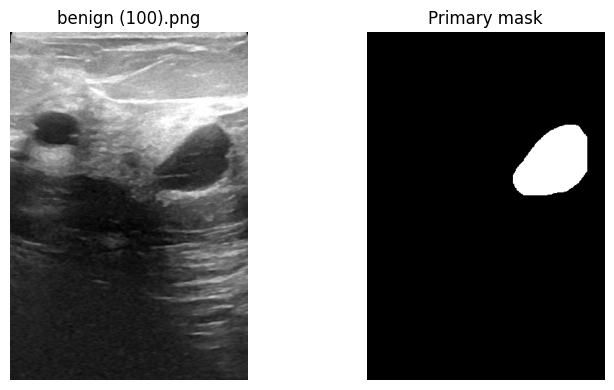

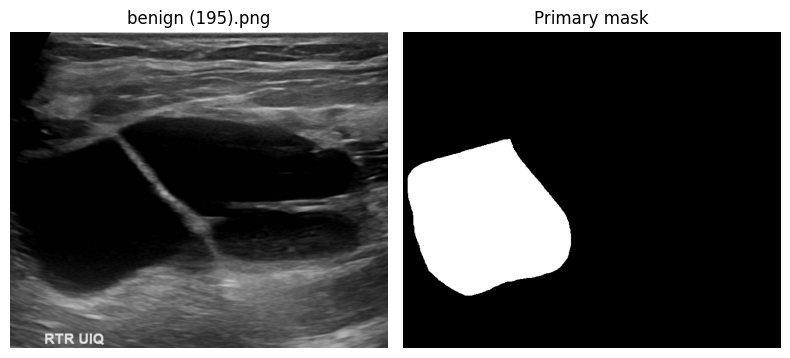

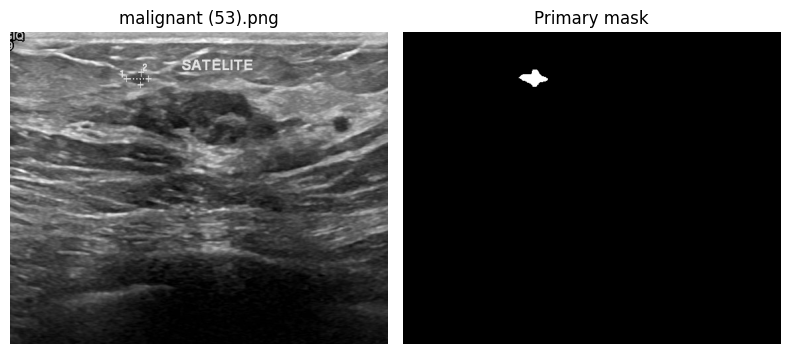

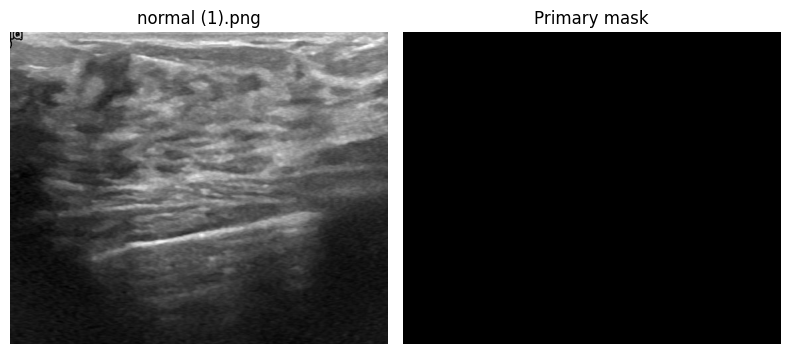

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

names = [
    "benign (100).png",
    "benign (195).png",
    "malignant (53).png",
    "normal (1).png"
]

for name in names:
    folder = "normal" if name.startswith("normal") else (
        "malignant" if name.startswith("malignant") else "benign"
    )

    img_path = DATASET_PATH / folder / name
    mask_path = DATASET_PATH / folder / (img_path.stem + "_mask.png")

    img = Image.open(img_path).convert("RGB")
    mask = Image.open(mask_path).convert("L")

    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(img)
    ax[0].set_title(name)
    ax[1].imshow(mask, cmap="gray")
    ax[1].set_title("Primary mask")

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.show()

Inspect all Annotation for One Image


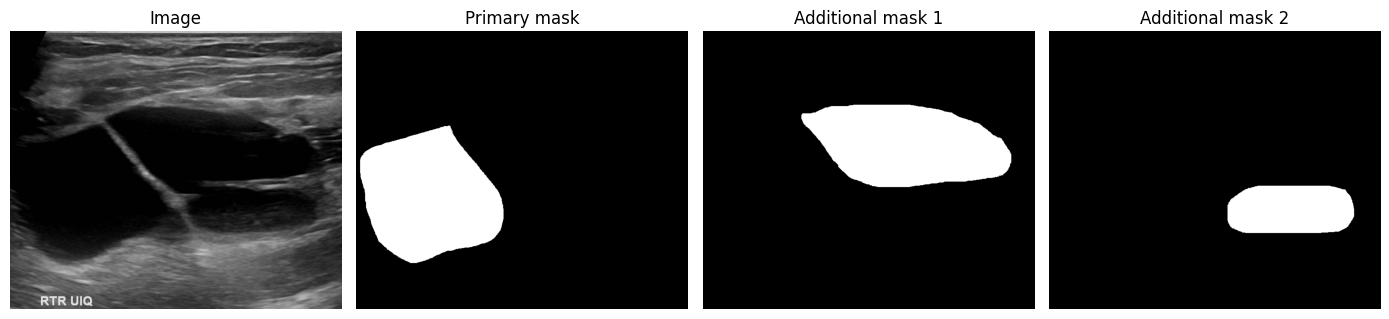

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

folder = DATASET_PATH / "benign"
name = "benign (195)"

img = Image.open(folder / f"{name}.png").convert("RGB")

m1 = Image.open(folder / f"{name}_mask.png").convert("L")
m2 = Image.open(folder / f"{name}_mask_1.png").convert("L")
m3 = Image.open(folder / f"{name}_mask_2.png").convert("L")

fig, ax = plt.subplots(1, 4, figsize=(14, 4))

ax[0].imshow(img)
ax[0].set_title("Image")

ax[1].imshow(m1, cmap="gray")
ax[1].set_title("Primary mask")

ax[2].imshow(m2, cmap="gray")
ax[2].set_title("Additional mask 1")

ax[3].imshow(m3, cmap="gray")
ax[3].set_title("Additional mask 2")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

Check How Many Images need Combined Masks

In [ ]:
from pathlib import Path

extra_count = 0
mask_count = 0

for category in ["benign", "malignant", "normal"]:
    folder = DATASET_PATH / category

    for img in folder.glob("*.png"):
        if "_mask" in img.stem:
            continue

        masks = list(folder.glob(img.stem + "_mask*.png"))

        if len(masks) > 1:
            extra_count += 1
            mask_count += len(masks)

print("Images with multiple masks:", extra_count)
print("Masks belonging to those images:", mask_count)

Images with multiple masks: 17
Masks belonging to those images: 35


PreProcessing Pipeline

In [ ]:

import numpy as np
from PIL import Image
from pathlib import Path
from tqdm import tqdm

DATASET_PATH = Path("/content/BUSI_Extracted/Dataset_BUSI_with_GT")
OUT_PATH = Path("/content/BUSI_Processed")
SIZE = (256, 256)

OUT_PATH.mkdir(exist_ok=True)

for category in ["benign", "malignant", "normal"]:
    (OUT_PATH / category / "images").mkdir(parents=True, exist_ok=True)
    (OUT_PATH / category / "masks").mkdir(parents=True, exist_ok=True)

    folder = DATASET_PATH / category
    images = sorted(
        p for p in folder.glob("*.png")
        if "_mask" not in p.stem.lower()
    )

    for img_path in tqdm(images, desc=category):
        mask_paths = sorted(folder.glob(img_path.stem + "_mask*.png"))

        img = Image.open(img_path).convert("RGB")
        img = img.resize(SIZE, Image.Resampling.BILINEAR)

        combined = np.zeros(
            Image.open(mask_paths[0]).size[::-1], dtype=np.uint8
        )

        for mask_path in mask_paths:
            mask = np.array(Image.open(mask_path).convert("L"))
            combined = np.maximum(combined, mask)

        combined = (combined > 0).astype(np.uint8) * 255
        mask_img = Image.fromarray(combined)
        mask_img = mask_img.resize(SIZE, Image.Resampling.NEAREST)

        img.save(OUT_PATH / category / "images" / img_path.name)
        mask_img.save(OUT_PATH / category / "masks" / img_path.name)

print("Preprocessing completed!")


normal: 100%|██████████| 133/133 [00:04<00:00, 26.60it/s]

Preprocessing completed!


Validate PreProcessed images


In [ ]:
from pathlib import Path
import numpy as np
from PIL import Image

base = Path("/content/BUSI_Processed")

total = 0
errors = []
normal_empty = 0

for category in ["benign", "malignant", "normal"]:
    img_dir = base / category / "images"
    mask_dir = base / category / "masks"

    images = list(img_dir.glob("*.png"))

    for img_path in images:
        mask_path = mask_dir / img_path.name

        try:
            img = Image.open(img_path)
            mask = np.array(Image.open(mask_path).convert("L"))

            if img.size != (256, 256) or mask.shape != (256, 256):
                errors.append(img_path.name)

            if category == "normal" and mask.max() == 0:
                normal_empty += 1

            total += 1

        except Exception as e:
            errors.append((img_path.name, str(e)))

    print(category, ":", len(images), "images")

print("\nTotal checked:", total)
print("Errors:", len(errors))
print("Normal images with empty masks:", normal_empty)

if errors:
    print(errors[:10])

benign : 437 images
malignant : 210 images
normal : 133 images

Total checked: 780
Errors: 0
Normal images with empty masks: 133


Create Train , Validation , Splits ( Using 70:15:15 )

In [ ]:

import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

base = Path("/content/BUSI_Processed")
rows = []

for category in ["benign", "malignant", "normal"]:
    img_dir = base / category / "images"

    for img_path in img_dir.glob("*.png"):
        rows.append({
            "image": str(img_path),
            "mask": str(base / category / "masks" / img_path.name),
            "category": category
        })

df = pd.DataFrame(rows)

train, temp = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["category"]
)

val, test = train_test_split(
    temp,
    test_size=0.50,
    random_state=42,
    stratify=temp["category"]
)

out = Path("/content/drive/MyDrive/AI512_Project/splits")
out.mkdir(parents=True, exist_ok=True)

train.to_csv(out / "train.csv", index=False)
val.to_csv(out / "val.csv", index=False)
test.to_csv(out / "test.csv", index=False)

print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))
print("\nCategory counts:")
print(pd.crosstab(
    pd.concat([
        train.assign(split="train"),
        val.assign(split="val"),
        test.assign(split="test")
    ])["split"],
    pd.concat([
        train.assign(split="train"),
        val.assign(split="val"),
        test.assign(split="test")
    ])["category"]
))


Train: 546
Validation: 117
Test: 117

Category counts:
category  benign  malignant  normal
split                              
test          66         31      20
train        306        147      93
val           65         32      20


PyTorch DataLoader

In [ ]:

import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pathlib import Path
import numpy as np

split_dir = Path("/content/drive/MyDrive/AI512_Project/splits")

class BUSIDataset(Dataset):
    def __init__(self, csv_file):
        self.data = pd.read_csv(csv_file)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        img = Image.open(row["image"]).convert("RGB")
        mask = Image.open(row["mask"]).convert("L")

        img = np.array(img, dtype=np.float32) / 255.0
        mask = np.array(mask, dtype=np.uint8)
        mask = (mask > 0).astype(np.float32)

        img = torch.tensor(img).permute(2, 0, 1)
        mask = torch.tensor(mask).unsqueeze(0)

        return img, mask

train_ds = BUSIDataset(split_dir / "train.csv")
val_ds = BUSIDataset(split_dir / "val.csv")
test_ds = BUSIDataset(split_dir / "test.csv")

train_loader = DataLoader(
    train_ds, batch_size=8, shuffle=True
)

images, masks = next(iter(train_loader))

print("Train samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Test samples:", len(test_ds))
print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image range:", images.min().item(), images.max().item())
print("Mask values:", torch.unique(masks))


Train samples: 546
Validation samples: 117
Test samples: 117
Image batch shape: torch.Size([8, 3, 256, 256])
Mask batch shape: torch.Size([8, 1, 256, 256])
Image range: 0.0 1.0
Mask values: tensor([0., 1.])


Importing Model

In [ ]:
!git clone https://github.com/wurenkai/UltraLight-VM-UNet.git

Cloning into 'UltraLight-VM-UNet'...
remote: Enumerating objects: 119, done.
remote: Counting objects: 100% (63/63), done.
remote: Compressing objects: 100% (42/42), done.
remote: Total 119 (delta 47), reused 22 (delta 21), pack-reused 56 (from 1)
Receiving objects: 100% (119/119), 54.44 KiB | 995.00 KiB/s, done.
Resolving deltas: 100% (64/64), done.


In [ ]:
%cd /content/UltraLight-VM-UNet
!ls

/content/UltraLight-VM-UNet
configs      engine.py	loader.py  README.md  test.py	utils.py
dataprepare  LICENSE	models	   results    train.py


Inspect the configuration and setup instructions

In [ ]:
!cat README.md

<div align="center">
<h1>UltraLight VM-UNet </h1>
<h3>Parallel Vision Mamba Significantly Reduces Parameters for Skin Lesion Segmentation</h3>

Renkai Wu, Yinghao Liu, Guochen Ning, Pengchen Liang\*, Qing Chang\*


Cell Patterns ([j.patter.2025.101298](https://doi.org/10.1016/j.patter.2025.101298)) 



</div>

## 🔥🔥Highlights🔥🔥
### *1.The UltraLight VM-UNet has only 0.049M parameters, 0.060 GFLOPs, and a model weight file of only 229.1 KB.*</br>
### *2.Parallel Vision Mamba (or Mamba) is a winner for lightweight models.*</br>

## News🚀
(2025.05.30) ***The final version has been accepted by Patterns, a Cell subsidiary journal.***

(2024.04.24) ***The third version of our paper has been uploaded to [arXiv](https://arxiv.org/abs/2403.20035), adding richer experimental validation. These include not limited to:***
- Adding key parameter analysis of Mamba variants.
- Adding experiments on parallel connection of multiple Mamba variants.
- Adding the exploration of plug-and-play PVM Layer.
- A

In [ ]:
!find configs -maxdepth 2 -type f
!find models -maxdepth 2 -type f
!cat train.py

configs/config_setting.py
models/UltraLight_VM_UNet.py
import torch
from torch import nn
from torch.cuda.amp import autocast, GradScaler
from torch.utils.data import DataLoader
from loader import *

from models.UltraLight_VM_UNet import UltraLight_VM_UNet
from engine import *
import os
import sys
os.environ["CUDA_VISIBLE_DEVICES"] = "0" # "0, 1, 2, 3"

from utils import *
from configs.config_setting import setting_config

import warnings
warnings.filterwarnings("ignore")


def main(config):

    print('#----------Creating logger----------#')
    sys.path.append(config.work_dir + '/')
    log_dir = os.path.join(config.work_dir, 'log')
    checkpoint_dir = os.path.join(config.work_dir, 'checkpoints')
    resume_model = os.path.join(checkpoint_dir, 'latest.pth')
    outputs = os.path.join(config.work_dir, 'outputs')
    if not os.path.exists(checkpoint_dir):
        os.makedirs(checkpoint_dir)
    if not os.path.exists(outputs):
        os.makedirs(outputs)

    global logger
    logger =

Saving the Preprocessed data


In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

# !cp -r /content/BUSI_Processed /content/drive/MyDrive/AI512_Project/

In [ ]:
from pathlib import Path

path = Path("/content/drive/MyDrive/AI512_Project/BUSI_Processed")

print("Dataset folder exists:", path.exists())

for category in ["benign", "malignant", "normal"]:
    images = len(list((path / category / "images").glob("*.png")))
    masks = len(list((path / category / "masks").glob("*.png")))
    print(f"{category}: {images} images, {masks} masks")

Dataset folder exists: True
benign: 437 images, 437 masks
malignant: 210 images, 210 masks
normal: 133 images, 133 masks


GPU Availbility

In [ ]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch CUDA available:", torch.cuda.is_available())

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA: 13.0
GPU: Tesla T4
PyTorch CUDA available: True


In [ ]:
%cd /content/UltraLight-VM-UNet

!grep -n -i -E "mamba|torch|python|install|environment" README.md
!find . -maxdepth 2 -type f \( -iname "*requirement*" -o -iname "*environment*" -o -iname "setup.py" \)

/content/UltraLight-VM-UNet
3:<h3>Parallel Vision Mamba Significantly Reduces Parameters for Skin Lesion Segmentation</h3>
16:### *2.Parallel Vision Mamba (or Mamba) is a winner for lightweight models.*</br>
22:- Adding key parameter analysis of Mamba variants.
23:- Adding experiments on parallel connection of multiple Mamba variants.
36:Traditionally for improving the segmentation performance of models, most approaches prefer to use adding more complex modules. And this is not suitable for the medical field, especially for mobile medical devices, where computationally loaded models are not suitable for real clinical environments due to computational resource constraints. Recently, state-space models (SSMs), represented by Mamba, have become a strong competitor to traditional CNNs and Transformers. In this paper, we deeply explore the key elements of parameter influence in Mamba and propose an UltraLight Vision Mamba UNet (UltraLight VM-UNet) based on this. Specifically, we propose a m

In [ ]:
%cd /content/UltraLight-VM-UNet

!pip install ninja packaging

/content/UltraLight-VM-UNet


In [ ]:
!pip index versions mamba-ssm
!pip index versions causal-conv1d

mamba-ssm (2.3.2.post1)
Available versions: 2.3.2.post1, 2.3.1, 2.3.0, 2.2.6.post3, 2.2.5, 2.2.4, 2.2.3.post2, 2.2.2, 2.2.1, 2.2.0, 2.1.0, 2.0.4, 2.0.3, 2.0.2, 2.0.1, 2.0.0, 1.2.2, 1.2.1, 1.2.0.post1, 1.2.0, 1.1.4, 1.1.3.post1, 1.1.2, 1.1.1, 1.1.0, 1.0.1
causal-conv1d (1.7.0)
Available versions: 1.7.0, 1.6.2.post1, 1.6.1, 1.6.0, 1.5.3.post1, 1.5.2, 1.5.1, 1.5.0.post8, 1.5.0.post5, 1.4.0, 1.3.0.post1, 1.2.2.post1, 1.2.1, 1.2.0.post2, 1.2.0.post1, 1.1.3.post1, 1.1.2.post1, 1.1.1, 1.1.0, 1.0.2, 1.0.1, 1.0.0


In [ ]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA: 13.0
GPU available: True


In [ ]:
%pip install --no-deps "https://github.com/Dao-AILab/causal-conv1d/releases/download/v1.6.2.post1/causal_conv1d-1.6.2.post1%2Bcu13torch2.10cxx11abiTRUE-cp313-cp313-linux_x86_64.whl"

%pip install --no-deps "https://github.com/state-spaces/mamba/releases/download/v2.3.2.post1/mamba_ssm-2.3.2.post1%2Bcu13torch2.10cxx11abiTRUE-cp313-cp313-linux_x86_64.whl"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 205.8/205.8 MB 30.2 MB/s  0:00:06
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 349.5/349.5 MB 36.0 MB/s  0:00:08


In [ ]:
import torch
import sys

sys.path.insert(0, "/content/UltraLight-VM-UNet")

from mamba_ssm import Mamba
from models.UltraLight_VM_UNet import UltraLight_VM_UNet

model = UltraLight_VM_UNet(
    num_classes=1,
    input_channels=3,
    c_list=[8, 16, 24, 32, 48, 64],
    split_att="fc",
    bridge=True
).cuda()

x = torch.randn(1, 3, 256, 256, device="cuda")

model.eval()
with torch.no_grad():
    y = model(x)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Output shape:", tuple(y.shape))
print("Output finite:", torch.isfinite(y).all().item())
print("Parameters:", sum(p.numel() for p in model.parameters()))

SC_Att_Bridge was used
Python: 3.13.16
PyTorch: 2.11.0+cu130
Output shape: (1, 1, 256, 256)
Output finite: True
Parameters: 49457


In [ ]:
%cd /content/UltraLight-VM-UNet

!pip download --only-binary=:all: --no-deps \
  mamba-ssm==2.3.2.post1 \
  -d /content/mamba_wheel_test

/content/UltraLight-VM-UNet
ERROR: Could not find a version that satisfies the requirement mamba-ssm==2.3.2.post1 (from versions: none)
ERROR: No matching distribution found for mamba-ssm==2.3.2.post1


In [ ]:
%cd /content/UltraLight-VM-UNet

!pip download --no-deps --no-binary=:all: \
  mamba-ssm==1.0.1 \
  -d /content/mamba_source_test

/content/UltraLight-VM-UNet
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'mamba-ssm' when getting requirements to build wheel


In [ ]:
import tarfile

archive = "/content/mamba_source_test/mamba_ssm-1.0.1.tar.gz"

with tarfile.open(archive, "r:gz") as tar:
    for name in tar.getnames():
        if name.endswith(("setup.py", "pyproject.toml")):
            print(f"\n--- {name} ---")
            f = tar.extractfile(name)
            if f:
                print(f.read().decode("utf-8", errors="replace")[:12000])

FileNotFoundError: [Errno 2] No such file or directory: '/content/mamba_source_test/mamba_ssm-1.0.1.tar.gz'

Checking CUDA Availblity

In [ ]:
import torch
from torch.utils.cpp_extension import CUDA_HOME
import shutil

print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("CUDA_HOME:", CUDA_HOME)
print("nvcc path:", shutil.which("nvcc"))

if shutil.which("nvcc"):
    !nvcc --version

In [ ]:
import torch
from torch.utils.cpp_extension import CUDA_HOME

print("CUDA toolkit:", CUDA_HOME)
print("PyTorch C++11 ABI:", torch._C._GLIBCXX_USE_CXX11_ABI)
print("GPU capability:", torch.cuda.get_device_capability(0))
print("CUDA architectures:", torch.cuda.get_arch_list())

Get Mamba Imported

In [ ]:
import tarfile

archive = "/content/mamba_source_test/mamba_ssm-1.0.1.tar.gz"

with tarfile.open(archive, "r:gz") as tar:
    for name in tar.getnames():
        if name.endswith("selective_scan_interface.py"):
            print(f"\n--- {name} ---")
            f = tar.extractfile(name)
            if f:
                print(f.read().decode("utf-8", errors="replace")[:9000])

In [ ]:
%cd /content/UltraLight-VM-UNet

!pip download --no-deps --no-binary=:all: causal-conv1d==1.0.0 -d /content/causal_source_test

In [ ]:
import tarfile

archive = "/content/causal_source_test/causal_conv1d-1.0.0.tar.gz"

with tarfile.open(archive, "r:gz") as tar:
    for name in tar.getnames():
        if name.endswith("setup.py"):
            print(f"\n--- {name} ---")
            f = tar.extractfile(name)
            if f:
                print(f.read().decode("utf-8", errors="replace")[:10000])

In [ ]:

import tarfile

archive = "/content/mamba_source_test/mamba_ssm-1.0.1.tar.gz"

with tarfile.open(archive, "r:gz") as tar:
    for name in tar.getnames():
        if name.endswith("setup.py"):
            print(f"\n--- {name} ---")
            f = tar.extractfile(name)
            if f:
                print(f.read().decode("utf-8", errors="replace")[:14000])
            break


In [ ]:

import torch
import timm
import einops

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

try:
    import mamba_ssm
    print("Mamba:", mamba_ssm.__version__)
except Exception as e:
    print("Mamba import:", repr(e))

try:
    import causal_conv1d
    print("Causal Conv1D:", getattr(causal_conv1d, "__version__", "imported"))
except Exception as e:
    print("Causal Conv1D import:", repr(e))


In [ ]:

%pip install --no-cache-dir --no-build-isolation \
"https://github.com/Dao-AILab/causal-conv1d/releases/download/v1.5.0.post8/causal_conv1d-1.5.0.post8+cu12torch2.6cxx11abiFALSE-cp311-cp311-linux_x86_64.whl"

%pip install --no-cache-dir --no-build-isolation \
"https://github.com/state-spaces/mamba/releases/download/v2.2.3.post2/mamba_ssm-2.2.3.post2+cu12torch2.6cxx11abiFALSE-cp311-cp311-linux_x86_64.whl"


In [ ]:

from mamba_ssm import Mamba
import causal_conv1d
import torch

print("Mamba and Causal Conv1D imported successfully!")
print("GPU:", torch.cuda.get_device_name(0))


In [ ]:
%pip show mamba-ssm causal-conv1d

Testing Model

In [ ]:
import sys

sys.path.insert(0, "/content/UltraLight-VM-UNet")

import torch
from models.UltraLight_VM_UNet import UltraLight_VM_UNet

model = UltraLight_VM_UNet(
    num_classes=1,
    input_channels=3,
    c_list=[8, 16, 24, 32, 48, 64],
    split_att="fc",
    bridge=True,
)

model = model.cuda().eval()

x = torch.randn(1, 3, 256, 256, device="cuda")

with torch.no_grad():
    y = model(x)

print("Input shape:", x.shape)
print("Output shape:", y.shape)
print("Output range:", y.min().item(), y.max().item())
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("GPU:", torch.cuda.get_device_name(0))

Verify pre processed pipeline

In [ ]:
import os
import pandas as pd

base = "/content/drive/MyDrive/AI512_Project"

for f in [
    f"{base}/splits/train.csv",
    f"{base}/splits/val.csv",
    f"{base}/splits/test.csv",
]:
    df = pd.read_csv(f)
    print(f"\n{os.path.basename(f)}: {len(df)} samples")
    print(df.head(2).to_string(index=False))

print("\nProcessed dataset exists:",
      os.path.exists("/content/drive/MyDrive/AI512_Project/BUSI_Processed"))

Inspect the Original Loss and Training Configuration

In [ ]:

import os

repo = "/content/UltraLight-VM-UNet"

for root, dirs, files in os.walk(repo):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
    for name in files:
        if name.endswith(".py") and any(
            key in name.lower()
            for key in ["loss", "train", "engine", "config"]
        ):
            path = os.path.join(root, name)
            print(f"\n{'='*20} {path} {'='*20}")
            try:
                with open(path, "r", encoding="utf-8") as f:
                    content = f.read()
                print(content[:9000])
            except Exception as e:
                print("Could not read:", e)


Checking if the Extracted Files are Linked to the Current Repo ( Pipeline )

In [ ]:

import os
import pandas as pd

train_csv = "/content/drive/MyDrive/AI512_Project/splits/train.csv"
df = pd.read_csv(train_csv)

print("First image exists:", os.path.exists(df.iloc[0]["image"]))
print("First mask exists:", os.path.exists(df.iloc[0]["mask"]))
print("Train samples:", len(df))
print("GPU available:", __import__("torch").cuda.is_available())


Checkpoint 1 ( Saving all the data till now )

In [ ]:
# # Install missing dependency
# !pip install thop -q


# # Comment Out If need to re train model
# import os
# import sys
# import random
# import numpy as np
# import pandas as pd
# from PIL import Image

# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# from torch.utils.data import Dataset, DataLoader

# sys.path.insert(0, "/content/UltraLight-VM-UNet")
# from models.UltraLight_VM_UNet import UltraLight_VM_UNet
# from utils import BceDiceLoss

# # Paths
# DRIVE = "/content/drive/MyDrive/AI512_Project"
# OUT = os.path.join(DRIVE, "baseline_results")
# os.makedirs(OUT, exist_ok=True)

# # Reproducibility
# seed = 42
# random.seed(seed)
# np.random.seed(seed)
# torch.manual_seed(seed)
# torch.cuda.manual_seed_all(seed)

# device = torch.device("cuda")

# class BUSIDataset(Dataset):
#     def __init__(self, csv_path):
#         self.df = pd.read_csv(csv_path)

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, idx):
#         row = self.df.iloc[idx]

#         img = Image.open(row["image"]).convert("RGB").resize(
#             (256, 256), Image.Resampling.BILINEAR
#         )
#         mask = Image.open(row["mask"]).convert("L").resize(
#             (256, 256), Image.Resampling.NEAREST
#         )

#         img = np.asarray(img, dtype=np.float32) / 255.0
#         mask = (np.asarray(mask, dtype=np.float32) > 0).astype(np.float32)

#         img = torch.from_numpy(img.transpose(2, 0, 1).copy())
#         mask = torch.from_numpy(mask[None].copy())

#         return img, mask

# train_ds = BUSIDataset(f"{DRIVE}/splits/train.csv")
# val_ds = BUSIDataset(f"{DRIVE}/splits/val.csv")

# train_loader = DataLoader(
#     train_ds, batch_size=8, shuffle=True,
#     num_workers=2, pin_memory=True
# )
# val_loader = DataLoader(
#     val_ds, batch_size=1, shuffle=False,
#     num_workers=2, pin_memory=True
# )

# model = UltraLight_VM_UNet(
#     num_classes=1,
#     input_channels=3,
#     c_list=[8, 16, 24, 32, 48, 64],
#     split_att="fc",
#     bridge=True
# ).to(device)

# criterion = BceDiceLoss()
# optimizer = torch.optim.AdamW(
#     model.parameters(), lr=0.001, weight_decay=0.01
# )
# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer, T_max=50, eta_min=1e-5
# )

# def calculate_metrics(pred, target):
#     pred = pred >= 0.5
#     target = target >= 0.5

#     intersection = (pred & target).sum().item()
#     pred_sum = pred.sum().item()
#     target_sum = target.sum().item()
#     union = pred_sum + target_sum - intersection

#     dice = (2 * intersection + 1e-7) / (
#         pred_sum + target_sum + 1e-7
#     )
#     iou = (intersection + 1e-7) / (union + 1e-7)
#     return dice, iou

# best_val_loss = float("inf")
# history = []

# print("Starting UltraLight VM-UNet baseline training")
# print("Train:", len(train_ds), "| Validation:", len(val_ds))
# print("Device:", torch.cuda.get_device_name(0))

# for epoch in range(1, 51):
#     model.train()
#     train_losses = []

#     for images, masks in train_loader:
#         images = images.to(device, non_blocking=True)
#         masks = masks.to(device, non_blocking=True)

#         optimizer.zero_grad(set_to_none=True)
#         outputs = model(images)
#         loss = criterion(outputs, masks)
#         loss.backward()
#         optimizer.step()
#         train_losses.append(loss.item())

#     model.eval()
#     val_losses = []
#     val_dice = []
#     val_iou = []

#     with torch.no_grad():
#         for images, masks in val_loader:
#             images = images.to(device, non_blocking=True)
#             masks = masks.to(device, non_blocking=True)

#             outputs = model(images)
#             loss = criterion(outputs, masks)
#             val_losses.append(loss.item())

#             dice, iou = calculate_metrics(outputs, masks)
#             val_dice.append(dice)
#             val_iou.append(iou)

#     scheduler.step()

#     train_loss = float(np.mean(train_losses))
#     val_loss = float(np.mean(val_losses))
#     mean_dice = float(np.mean(val_dice))
#     mean_iou = float(np.mean(val_iou))

#     record = {
#         "epoch": epoch,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_dice": mean_dice,
#         "val_iou": mean_iou,
#         "lr": optimizer.param_groups[0]["lr"]
#     }
#     history.append(record)
#     pd.DataFrame(history).to_csv(
#         os.path.join(OUT, "training_log.csv"), index=False
#     )

#     if val_loss < best_val_loss:
#         best_val_loss = val_loss
#         torch.save(
#             {
#                 "epoch": epoch,
#                 "model_state_dict": model.state_dict(),
#                 "optimizer_state_dict": optimizer.state_dict(),
#                 "val_loss": val_loss,
#                 "val_dice": mean_dice,
#                 "val_iou": mean_iou
#             },
#             os.path.join(OUT, "best_model.pth")
#         )

#     print(
#         f"Epoch {epoch:02d}/50 | "
#         f"Train Loss: {train_loss:.4f} | "
#         f"Val Loss: {val_loss:.4f} | "
#         f"Val Dice: {mean_dice:.4f} | "
#         f"Val IoU: {mean_iou:.4f}"
#     )

# print("\nTraining complete.")
# print("Best validation loss:", best_val_loss)
# print("Results saved to:", OUT)

Evaluate the Baseline

In [ ]:
import os
import pandas as pd

result_dir = "/content/drive/MyDrive/AI512_Project/baseline_results"

print("Files:", os.listdir(result_dir))

log_path = os.path.join(result_dir, "training_log.csv")
checkpoint_path = os.path.join(result_dir, "best_model.pth")

if os.path.exists(log_path):
    log = pd.read_csv(log_path)
    print("\nLast training records:")
    display(log.tail())

print("\nCheckpoint exists:", os.path.exists(checkpoint_path))

Baseline test set Evaluation

In [ ]:
import os
import torch
import pandas as pd
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix

# Paths
project_dir = "/content/drive/MyDrive/AI512_Project"
result_dir = os.path.join(project_dir, "baseline_results")
checkpoint_path = os.path.join(result_dir, "best_model.pth")
test_csv = os.path.join(project_dir, "splits", "test.csv")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load test dataset
test_df = pd.read_csv(test_csv)
test_ds = BUSIDataset(test_csv)
test_loader = DataLoader(test_ds, batch_size=1, shuffle=False)

# Recreate the original model architecture
model = UltraLight_VM_UNet(
    num_classes=1,
    input_channels=3,
    c_list=[8, 16, 24, 32, 48, 64],
    split_att="fc",
    bridge=True
).to(device)

# Load the saved best checkpoint
checkpoint = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Checkpoint epoch:", checkpoint.get("epoch", "Not recorded"))
print("Test images:", len(test_ds))

In [ ]:
import numpy as np

total_intersection = 0
total_union = 0
total_pred = 0
total_target = 0
sample_dice = []
sample_iou = []
positive_dice = []
positive_iou = []

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = (masks.to(device) >= 0.5)

        outputs = model(images)
        preds = outputs >= 0.5

        intersection = (preds & masks).sum().item()
        union = (preds | masks).sum().item()
        pred_sum = preds.sum().item()
        target_sum = masks.sum().item()

        dice = (2 * intersection + 1e-7) / (pred_sum + target_sum + 1e-7)
        iou = (intersection + 1e-7) / (union + 1e-7)

        sample_dice.append(dice)
        sample_iou.append(iou)

        if target_sum > 0:
            positive_dice.append(dice)
            positive_iou.append(iou)

        total_intersection += intersection
        total_union += union
        total_pred += pred_sum
        total_target += target_sum

print(f"Test images: {len(test_ds)}")
print(f"Pixel-level Dice: {(2*total_intersection+1e-7)/(total_pred+total_target+1e-7):.4f}")
print(f"Pixel-level IoU: {(total_intersection+1e-7)/(total_union+1e-7):.4f}")
print(f"Mean image Dice: {np.mean(sample_dice):.4f}")
print(f"Mean image IoU: {np.mean(sample_iou):.4f}")
print(f"Lesion-positive images: {len(positive_dice)}")
print(f"Lesion-positive mean Dice: {np.mean(positive_dice):.4f}")
print(f"Lesion-positive mean IoU: {np.mean(positive_iou):.4f}")

Visualize Predictions

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

model.eval()
shown = 0

fig, axes = plt.subplots(6, 3, figsize=(12, 22))

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        outputs = model(images)

        image = images[0].cpu().permute(1, 2, 0).numpy()
        mask = masks[0, 0].cpu().numpy()
        pred = (outputs[0, 0].cpu().numpy() >= 0.5).astype(np.float32)

        # Undo normalization if your dataset uses normalization.
        image = np.clip(image, 0, 1)

        axes[shown, 0].imshow(image)
        axes[shown, 0].set_title("Ultrasound")

        axes[shown, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[shown, 1].set_title("Ground Truth")

        axes[shown, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
        axes[shown, 2].set_title("Prediction")

        for ax in axes[shown]:
            ax.axis("off")

        shown += 1
        if shown == 6:
            break

plt.tight_layout()
plt.show()

E2 Implementation

In [ ]:
import torch
import torch.nn.functional as F

def get_boundary(mask):
    # mask shape: [B, 1, H, W]
    mask = (mask >= 0.5).float()

    dilated = F.max_pool2d(mask, kernel_size=3, stride=1, padding=1)
    eroded = 1.0 - F.max_pool2d(
        1.0 - mask, kernel_size=3, stride=1, padding=1
    )

    boundary = (dilated - eroded).clamp(0, 1)
    return boundary


def boundary_aware_loss(pred, target, original_loss, boundary_weight=3.0):
    target = (target >= 0.5).float()

    # Give pixels near lesion boundaries extra importance.
    boundary = get_boundary(target)
    pixel_weights = 1.0 + boundary_weight * boundary

    weighted_bce = F.binary_cross_entropy(
        pred.clamp(1e-7, 1 - 1e-7),
        target,
        reduction="none"
    )

    weighted_bce = (weighted_bce * pixel_weights).mean()

    base_loss = original_loss(pred, target)

    return base_loss + 0.5 * weighted_bce

Sanity Check the loss before training

In [ ]:
model.eval()

images, masks = next(iter(train_loader))
images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    predictions = model(images)
    boundary = get_boundary(masks)
    loss = boundary_aware_loss(
        predictions, masks, BceDiceLoss()
    )

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Predictions:", predictions.shape)
print("Boundary:", boundary.shape)
print("Boundary pixels:", int(boundary.sum().item()))
print("Test loss:", loss.item())
print("Loss finite:", torch.isfinite(loss).item())

NameError: name 'get_boundary' is not defined

E2 Implementation with Checkpoint

In [ ]:
# #Comment it out if u want to re train E2

# import os
# import pandas as pd
# import torch
# from torch.optim import AdamW
# from torch.optim.lr_scheduler import CosineAnnealingLR

# e2_dir = "/content/drive/MyDrive/AI512_Project/E2_boundary"
# os.makedirs(e2_dir, exist_ok=True)

# # Start from the original initialization for a fair comparison.
# # Do NOT load E1's trained checkpoint.
# model = UltraLight_VM_UNet(
#     num_classes=1,
#     input_channels=3,
#     c_list=[8, 16, 24, 32, 48, 64],
#     split_att="fc",
#     bridge=True
# ).to(device)

# criterion = BceDiceLoss()
# optimizer = AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
# scheduler = CosineAnnealingLR(
#     optimizer, T_max=50, eta_min=1e-5
# )

# best_val_loss = float("inf")
# history = []

# for epoch in range(50):
#     model.train()
#     train_loss_sum = 0.0

#     for images, masks in train_loader:
#         images = images.to(device)
#         masks = masks.to(device)

#         optimizer.zero_grad()
#         predictions = model(images)

#         loss = boundary_aware_loss(
#             predictions, masks, criterion, boundary_weight=3.0
#         )

#         loss.backward()
#         optimizer.step()
#         train_loss_sum += loss.item()

#     model.eval()
#     val_loss_sum = 0.0
#     intersection = 0
#     union = 0
#     pred_total = 0
#     target_total = 0

#     with torch.no_grad():
#         for images, masks in val_loader:
#             images = images.to(device)
#             masks = (masks.to(device) >= 0.5)

#             predictions = model(images)
#             loss = boundary_aware_loss(
#                 predictions, masks.float(), criterion, boundary_weight=3.0
#             )
#             val_loss_sum += loss.item()

#             preds = predictions >= 0.5
#             intersection += (preds & masks).sum().item()
#             union += (preds | masks).sum().item()
#             pred_total += preds.sum().item()
#             target_total += masks.sum().item()

#     train_loss = train_loss_sum / len(train_loader)
#     val_loss = val_loss_sum / len(val_loader)
#     val_dice = (2 * intersection + 1e-7) / (
#         pred_total + target_total + 1e-7
#     )
#     val_iou = (intersection + 1e-7) / (union + 1e-7)

#     scheduler.step()

#     record = {
#         "epoch": epoch + 1,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_dice": val_dice,
#         "val_iou": val_iou,
#         "lr": optimizer.param_groups[0]["lr"]
#     }
#     history.append(record)
#     pd.DataFrame(history).to_csv(
#         os.path.join(e2_dir, "training_log.csv"), index=False
#     )

#     if val_loss < best_val_loss:
#         best_val_loss = val_loss
#         torch.save({
#             "epoch": epoch + 1,
#             "model_state_dict": model.state_dict(),
#             "optimizer_state_dict": optimizer.state_dict(),
#             "val_loss": val_loss,
#             "val_dice": val_dice,
#             "val_iou": val_iou
#         }, os.path.join(e2_dir, "best_model.pth"))

#     print(
#         f"Epoch {epoch+1:02d}/50 | "
#         f"Train Loss: {train_loss:.4f} | "
#         f"Val Loss: {val_loss:.4f} | "
#         f"Val Dice: {val_dice:.4f} | "
#         f"Val IoU: {val_iou:.4f}"
#     )

# print("\nE2 training complete.")
# print("Best validation loss:", best_val_loss)
# print("Saved to:", e2_dir)

E2 on Test Set

In [ ]:
import os
import numpy as np
import torch

e2_checkpoint_path = (
    "/content/drive/MyDrive/AI512_Project/"
    "E2_boundary/best_model.pth"
)

checkpoint = torch.load(e2_checkpoint_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("E2 checkpoint epoch:", checkpoint["epoch"])

total_intersection = 0
total_union = 0
total_pred = 0
total_target = 0
sample_dice = []
sample_iou = []
positive_dice = []
positive_iou = []

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device) >= 0.5

        predictions = model(images)
        preds = predictions >= 0.5

        intersection = (preds & masks).sum().item()
        union = (preds | masks).sum().item()
        pred_sum = preds.sum().item()
        target_sum = masks.sum().item()

        dice = (2 * intersection + 1e-7) / (
            pred_sum + target_sum + 1e-7
        )
        iou = (intersection + 1e-7) / (union + 1e-7)

        sample_dice.append(dice)
        sample_iou.append(iou)

        if target_sum > 0:
            positive_dice.append(dice)
            positive_iou.append(iou)

        total_intersection += intersection
        total_union += union
        total_pred += pred_sum
        total_target += target_sum

results = {
    "pixel_dice": (2 * total_intersection + 1e-7) /
                  (total_pred + total_target + 1e-7),
    "pixel_iou": (total_intersection + 1e-7) /
                 (total_union + 1e-7),
    "mean_image_dice": np.mean(sample_dice),
    "mean_image_iou": np.mean(sample_iou),
    "lesion_positive_mean_dice": np.mean(positive_dice),
    "lesion_positive_mean_iou": np.mean(positive_iou)
}

for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

import pandas as pd
pd.DataFrame([results]).to_csv(
    "/content/drive/MyDrive/AI512_Project/E2_boundary/test_results.csv",
    index=False
)
print("Test results saved.")

Speckle Corruption and Consistency Loss

In [ ]:
import torch
import torch.nn.functional as F

def add_speckle_noise(images, noise_std=0.15):
    # Multiplicative noise, then keep image values in [0, 1].
    noise = torch.randn_like(images) * noise_std
    noisy_images = images * (1.0 + noise)
    return noisy_images.clamp(0.0, 1.0)


def e3_loss(model, images, masks, criterion, consistency_weight=0.1):
    # Clean prediction
    clean_pred = model(images)
    clean_loss = criterion(clean_pred, masks)

    # Corrupted prediction
    noisy_images = add_speckle_noise(images)
    noisy_pred = model(noisy_images)
    noisy_loss = criterion(noisy_pred, masks)

    # Encourage predictions to remain stable under corruption.
    consistency_loss = F.mse_loss(noisy_pred, clean_pred.detach())

    total_loss = (
        0.5 * clean_loss
        + 0.5 * noisy_loss
        + consistency_weight * consistency_loss
    )

    return total_loss, clean_loss.detach(), noisy_loss.detach(), consistency_loss.detach()

Sanity Check Before Training (E2)

In [ ]:
model.eval()

images, masks = next(iter(train_loader))
images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    total, clean, noisy, consistency = e3_loss(
        model, images, masks, BceDiceLoss()
    )

print("Total loss:", total.item())
print("Clean loss:", clean.item())
print("Noisy loss:", noisy.item())
print("Consistency loss:", consistency.item())
print("All finite:", all(torch.isfinite(x).item()
                         for x in [total, clean, noisy, consistency]))

Total loss: 1.416171669960022
Clean loss: 1.3899441957473755
Noisy loss: 1.4393976926803589
Consistency loss: 0.015007417649030685
All finite: True


E3 Training

In [ ]:
!pip install thop -q

In [ ]:
#Uncomment when necessary only to train E3

# import os
# import sys
# import pandas as pd
# import torch
# import torch.nn.functional as F
# from torch.utils.data import Dataset, DataLoader
# from PIL import Image
# import numpy as np
# from torch.optim import AdamW
# from torch.optim.lr_scheduler import CosineAnnealingLR
# from tqdm.auto import tqdm

# # Ensure the cloned repository path is in python sys path
# sys.path.insert(0, "/content/UltraLight-VM-UNet")
# from utils import BceDiceLoss
# from models.UltraLight_VM_UNet import UltraLight_VM_UNet

# # 1. Define Dataset Class
# class BUSIDataset(Dataset):
#     def __init__(self, csv_file):
#         self.data = pd.read_csv(csv_file)

#     def __len__(self):
#         return len(self.data)

#     def __getitem__(self, idx):
#         row = self.data.iloc[idx]
#         img = Image.open(row["image"]).convert("RGB")
#         mask = Image.open(row["mask"]).convert("L")

#         img = np.array(img, dtype=np.float32) / 255.0
#         mask = np.array(mask, dtype=np.uint8)
#         mask = (mask > 0).astype(np.float32)

#         img = torch.tensor(img).permute(2, 0, 1)
#         mask = torch.tensor(mask).unsqueeze(0)
#         return img, mask

# # 2. Instantiate Datasets and DataLoaders
# split_dir = Path("/content/drive/MyDrive/AI512_Project/splits")
# train_ds = BUSIDataset(split_dir / "train.csv")
# val_ds = BUSIDataset(split_dir / "val.csv")

# train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
# val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

# # 3. Helper functions for E3 Speckle Corruption & Loss
# def add_speckle_noise(images, noise_std=0.15):
#     noise = torch.randn_like(images) * noise_std
#     noisy_images = images * (1.0 + noise)
#     return noisy_images.clamp(0.0, 1.0)

# def e3_loss(model, images, masks, criterion, consistency_weight=0.1):
#     clean_pred = model(images)
#     clean_loss = criterion(clean_pred, masks)

#     noisy_images = add_speckle_noise(images)
#     noisy_pred = model(noisy_images)
#     noisy_loss = criterion(noisy_pred, masks)

#     consistency_loss = F.mse_loss(noisy_pred, clean_pred.detach())

#     total_loss = (
#         0.5 * clean_loss
#         + 0.5 * noisy_loss
#         + consistency_weight * consistency_loss
#     )
#     return total_loss, clean_loss.detach(), noisy_loss.detach(), consistency_loss.detach()

# # 4. Define the device variable
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # 5. Fresh model for E3
# model = UltraLight_VM_UNet(
#     num_classes=1,
#     input_channels=3
# ).to(device)

# criterion = BceDiceLoss()
# optimizer = AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
# scheduler = CosineAnnealingLR(
#     optimizer, T_max=50, eta_min=1e-5
# )

# epochs = 50
# save_dir = "/content/drive/MyDrive/AI512_Project/E3_corruption"
# os.makedirs(save_dir, exist_ok=True)

# best_val_loss = float("inf")
# history = []

# for epoch in range(epochs):
#     model.train()
#     train_loss = 0.0

#     for images, masks in tqdm(
#         train_loader, desc=f"E3 Epoch {epoch + 1}/{epochs}"
#     ):
#         images = images.to(device)
#         masks = masks.to(device)

#         optimizer.zero_grad()

#         total, clean, noisy, consistency = e3_loss(
#             model, images, masks, criterion,
#             consistency_weight=0.1
#         )

#         total.backward()
#         optimizer.step()
#         train_loss += total.item()

#     train_loss /= len(train_loader)

#     # Validate on clean images for consistent checkpoint selection
#     model.eval()
#     val_loss = 0.0
#     val_dice = 0.0
#     val_iou = 0.0

#     with torch.no_grad():
#         for images, masks in val_loader:
#             images = images.to(device)
#             masks = masks.to(device)

#             predictions = model(images)
#             loss = criterion(predictions, masks)
#             val_loss += loss.item()

#             pred_binary = (predictions >= 0.5).float()
#             intersection = (pred_binary * masks).sum(dim=(1, 2, 3))
#             pred_sum = pred_binary.sum(dim=(1, 2, 3))
#             mask_sum = masks.sum(dim=(1, 2, 3))

#             dice = (
#                 (2 * intersection + 1e-7)
#                 / (pred_sum + mask_sum + 1e-7)
#             )
#             iou = (
#                 (intersection + 1e-7)
#                 / (pred_sum + mask_sum - intersection + 1e-7)
#             )

#             val_dice += dice.mean().item()
#             val_iou += iou.mean().item()

#     val_loss /= len(val_loader)
#     val_dice /= len(val_loader)
#     val_iou /= len(val_loader)

#     scheduler.step()

#     history.append({
#         "epoch": epoch + 1,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_dice": val_dice,
#         "val_iou": val_iou,
#         "learning_rate": optimizer.param_groups[0]["lr"]
#     })

#     if val_loss < best_val_loss:
#         best_val_loss = val_loss
#         torch.save(
#             model.state_dict(),
#             os.path.join(save_dir, "best_model.pth")
#         )

#     pd.DataFrame(history).to_csv(
#         os.path.join(save_dir, "training_log.csv"),
#         index=False
#     )

#     print(
#         f"Epoch {epoch + 1:02d}/{epochs} | "
#         f"Train Loss: {train_loss:.4f} | "
#         f"Val Loss: {val_loss:.4f} | "
#         f"Val Dice: {val_dice:.4f} | "
#         f"Val IoU: {val_iou:.4f}"
#     )

# print("\nE3 training complete!")
# print("Best validation loss:", round(best_val_loss, 4))
# print("Saved to:", save_dir)

SC_Att_Bridge was used


E3 Epoch 1/50:   0%|          | 0/69 [00:00<?, ?it/s]

Epoch 01/50 | Train Loss: 1.2337 | Val Loss: 1.0315 | Val Dice: 0.2893 | Val IoU: 0.2073


E3 Epoch 2/50:   0%|          | 0/69 [00:00<?, ?it/s]

Epoch 02/50 | Train Loss: 0.9644 | Val Loss: 0.9578 | Val Dice: 0.3454 | Val IoU: 0.2442


E3 Epoch 3/50:   0%|          | 0/69 [00:00<?, ?it/s]

... (91 outputs left out)

E3 Epoch 49/50:   0%|          | 0/69 [00:00<?, ?it/s]

Epoch 49/50 | Train Loss: 0.4768 | Val Loss: 0.5559 | Val Dice: 0.6051 | Val IoU: 0.5042


E3 Epoch 50/50:   0%|          | 0/69 [00:00<?, ?it/s]

Epoch 50/50 | Train Loss: 0.4766 | Val Loss: 0.5560 | Val Dice: 0.6050 | Val IoU: 0.5042

E3 training complete!
Best validation loss: 0.5553
Saved to: /content/drive/MyDrive/AI512_Project/E3_corruption


Checkpoint E3 Corruption to Drive

In [ ]:
import os
import pandas as pd
import torch

e3_dir = "/content/drive/MyDrive/AI512_Project/E3_corruption"

checkpoint_path = os.path.join(e3_dir, "best_model.pth")
log_path = os.path.join(e3_dir, "training_log.csv")

print("Checkpoint exists:", os.path.exists(checkpoint_path))
print("Training log exists:", os.path.exists(log_path))

if os.path.exists(checkpoint_path):
    print("Checkpoint size (MB):",
          round(os.path.getsize(checkpoint_path) / (1024**2), 2))

if os.path.exists(log_path):
    e3_log = pd.read_csv(log_path)
    print("\nLog shape:", e3_log.shape)
    print("Columns:", e3_log.columns.tolist())
    print("\nLast 5 epochs:")
    display(e3_log.tail())

Checkpoint exists: True
Training log exists: True
Checkpoint size (MB): 0.23

Log shape: (50, 6)
Columns: ['epoch', 'train_loss', 'val_loss', 'val_dice', 'val_iou', 'learning_rate']

Last 5 epochs:


,epoch,train_loss,val_loss,val_dice,val_iou,learning_rate
45,46,0.470947,0.556949,0.605074,0.504141,0.000026
46,47,0.472391,0.555860,0.605106,0.504212,0.000019
47,48,0.474973,0.556295,0.603768,0.502545,0.000014
48,49,0.476829,0.555882,0.605097,0.504159,0.000011
49,50,0.476602,0.556021,0.605028,0.504151,0.000010


E4 Training

In [ ]:
#Uncomment to Train Again

# import os
# import sys
# import random
# import numpy as np
# import pandas as pd
# import torch
# import torch.nn.functional as F
# from torch.utils.data import Dataset, DataLoader
# from PIL import Image
# from pathlib import Path
# from tqdm.auto import tqdm

# # Ensure repository path is in python path
# sys.path.insert(0, "/content/UltraLight-VM-UNet")
# from utils import BceDiceLoss
# from models.UltraLight_VM_UNet import UltraLight_VM_UNet

# # Reproducibility
# SEED = 42
# random.seed(SEED)
# np.random.seed(SEED)
# torch.manual_seed(SEED)
# if torch.cuda.is_available():
#     torch.cuda.manual_seed_all(SEED)

# # Separate output directory. Do not overwrite E1, E2 or E3.
# E4_DIR = "/content/drive/MyDrive/AI512_Project/E4_combined"
# os.makedirs(E4_DIR, exist_ok=True)

# EPOCHS = 50
# CONSISTENCY_WEIGHT = 0.1
# BOUNDARY_WEIGHT = 3.0

# criterion = BceDiceLoss()

# # Define the device variable
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # Helper functions for E2 & E4 Boundary Losses
# def get_boundary(mask):
#     mask = (mask >= 0.5).float()
#     dilated = F.max_pool2d(mask, kernel_size=3, stride=1, padding=1)
#     eroded = 1.0 - F.max_pool2d(1.0 - mask, kernel_size=3, stride=1, padding=1)
#     boundary = (dilated - eroded).clamp(0, 1)
#     return boundary

# def boundary_aware_loss(pred, target, original_loss, boundary_weight=3.0):
#     target = (target >= 0.5).float()
#     boundary = get_boundary(target)
#     pixel_weights = 1.0 + boundary_weight * boundary
#     weighted_bce = F.binary_cross_entropy(
#         pred.clamp(1e-7, 1 - 1e-7),
#         target,
#         reduction="none"
#     )
#     weighted_bce = (weighted_bce * pixel_weights).mean()
#     base_loss = original_loss(pred, target)
#     return base_loss + 0.5 * weighted_bce

# # Helper functions for E3 & E4 Speckle Noise
# def add_speckle_noise(images, noise_std=0.15):
#     noise = torch.randn_like(images) * noise_std
#     noisy_images = images * (1.0 + noise)
#     return noisy_images.clamp(0.0, 1.0)

# def e4_loss(model, images, masks, criterion):
#     # Clean image prediction
#     clean_pred = model(images)
#     clean_loss = boundary_aware_loss(
#         clean_pred, masks, criterion,
#         boundary_weight=BOUNDARY_WEIGHT
#     )

#     # Multiplicative speckle-like corruption
#     noisy_images = add_speckle_noise(images, noise_std=0.15)
#     noisy_pred = model(noisy_images)
#     noisy_loss = boundary_aware_loss(
#         noisy_pred, masks, criterion,
#         boundary_weight=BOUNDARY_WEIGHT
#     )

#     # Encourage stable predictions under corruption
#     consistency_loss = F.mse_loss(
#         noisy_pred, clean_pred.detach()
#     )

#     total = (
#         0.5 * clean_loss
#         + 0.5 * noisy_loss
#         + CONSISTENCY_WEIGHT * consistency_loss
#     )
#     return total

# # Fresh initialization, NOT E2/E3 weights
# model = UltraLight_VM_UNet(
#     num_classes=1,
#     input_channels=3,
#     c_list=[8, 16, 24, 32, 48, 64],
#     split_att="fc",
#     bridge=True
# ).to(device)

# optimizer = torch.optim.AdamW(
#     model.parameters(), lr=0.001, weight_decay=0.01
# )
# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer, T_max=EPOCHS, eta_min=1e-5
# )

# def evaluate_clean(model, loader, criterion):
#     model.eval()
#     total_loss = 0.0
#     intersection = 0.0
#     pred_sum = 0.0
#     target_sum = 0.0

#     with torch.no_grad():
#         for images, masks in loader:
#             images = images.to(device)
#             masks = (masks.to(device) >= 0.5).float()
#             preds = model(images).clamp(0, 1)

#             loss = criterion(preds, masks)
#             total_loss += loss.item() * images.size(0)

#             binary = (preds >= 0.5).float()
#             intersection += (binary * masks).sum().item()
#             pred_sum += binary.sum().item()
#             target_sum += masks.sum().item()

#     eps = 1e-7
#     dice = (2 * intersection + eps) / (pred_sum + target_sum + eps)
#     iou = (intersection + eps) / (
#         pred_sum + target_sum - intersection + eps
#     )
#     return total_loss / len(loader.dataset), dice, iou

# history = []
# best_val_loss = float("inf")
# best_epoch = -1

# for epoch in range(1, EPOCHS + 1):
#     model.train()
#     running_loss = 0.0

#     progress = tqdm(
#         train_loader, desc=f"E4 Epoch {epoch}/{EPOCHS}"
#     )

#     for images, masks in progress:
#         images = images.to(device)
#         masks = (masks.to(device) >= 0.5).float()

#         optimizer.zero_grad(set_to_none=True)
#         loss = e4_loss(model, images, masks, criterion)

#         if not torch.isfinite(loss):
#             raise RuntimeError(
#                 f"Non-finite E4 loss at epoch {epoch}"
#             )

#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item() * images.size(0)
#         progress.set_postfix(loss=f"{loss.item():.4f}")

#     train_loss = running_loss / len(train_loader.dataset)

#     # Checkpoint selection uses clean validation loss
#     val_loss, val_dice, val_iou = evaluate_clean(
#         model, val_loader, criterion
#     )
#     scheduler.step()

#     lr = optimizer.param_groups[0]["lr"]
#     history.append({
#         "epoch": epoch,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_dice": val_dice,
#         "val_iou": val_iou,
#         "learning_rate": lr
#     })

#     pd.DataFrame(history).to_csv(
#         os.path.join(E4_DIR, "training_log.csv"), index=False
#     )

#     if val_loss < best_val_loss:
#         best_val_loss = val_loss
#         best_epoch = epoch
#         torch.save(
#             model.state_dict(),
#             os.path.join(E4_DIR, "best_model.pth")
#         )

#     print(
#         f"Epoch {epoch:02d}/{EPOCHS} | "
#         f"Train Loss: {train_loss:.4f} | "
#         f"Val Loss: {val_loss:.4f} | "
#         f"Val Dice: {val_dice:.4f} | "
#         f"Val IoU: {val_iou:.4f} | "
#         f"Best epoch: {best_epoch}"
#     )

# print("\nE4 training complete!")
# print(f"Best validation loss: {best_val_loss:.4f}")
# print(f"Best checkpoint epoch: {best_epoch}")
# print(f"Saved to: {E4_DIR}")

SC_Att_Bridge was used


E4 Epoch 1/50:   0%|          | 0/69 [00:00<?, ?it/s]

Epoch 01/50 | Train Loss: 1.2583 | Val Loss: 0.9663 | Val Dice: 0.3882 | Val IoU: 0.2409 | Best epoch: 1


E4 Epoch 2/50:   0%|          | 0/69 [00:00<?, ?it/s]

Epoch 02/50 | Train Loss: 1.0461 | Val Loss: 0.8862 | Val Dice: 0.5021 | Val IoU: 0.3352 | Best epoch: 2


E4 Epoch 3/50:   0%|          | 0/69 [00:00<?, ?it/s]

... (91 outputs left out)

E4 Epoch 49/50:   0%|          | 0/69 [00:00<?, ?it/s]

Epoch 49/50 | Train Loss: 0.4906 | Val Loss: 0.6409 | Val Dice: 0.6379 | Val IoU: 0.4684 | Best epoch: 23


E4 Epoch 50/50:   0%|          | 0/69 [00:00<?, ?it/s]

Epoch 50/50 | Train Loss: 0.4908 | Val Loss: 0.6406 | Val Dice: 0.6381 | Val IoU: 0.4685 | Best epoch: 23

E4 training complete!
Best validation loss: 0.6134
Best checkpoint epoch: 23
Saved to: /content/drive/MyDrive/AI512_Project/E4_combined


E4 Checkpoint

In [ ]:
import os
import pandas as pd

base = "/content/drive/MyDrive/AI512_Project"

for exp in ["baseline_results", "E2_boundary",
            "E3_corruption", "E4_combined"]:
    folder = os.path.join(base, exp)
    checkpoint = os.path.join(folder, "best_model.pth")
    log = os.path.join(folder, "training_log.csv")

    print(f"\n{exp}")
    print("Checkpoint exists:", os.path.exists(checkpoint))
    print("Log exists:", os.path.exists(log))

    if os.path.exists(log):
        df = pd.read_csv(log)
        print("Log shape:", df.shape)
        print("Columns:", df.columns.tolist())


baseline_results
Checkpoint exists: True
Log exists: True
Log shape: (50, 6)
Columns: ['epoch', 'train_loss', 'val_loss', 'val_dice', 'val_iou', 'lr']

E2_boundary
Checkpoint exists: True
Log exists: True
Log shape: (50, 6)
Columns: ['epoch', 'train_loss', 'val_loss', 'val_dice', 'val_iou', 'lr']

E3_corruption
Checkpoint exists: True
Log exists: True
Log shape: (50, 6)
Columns: ['epoch', 'train_loss', 'val_loss', 'val_dice', 'val_iou', 'learning_rate']

E4_combined
Checkpoint exists: True
Log exists: True
Log shape: (50, 6)
Columns: ['epoch', 'train_loss', 'val_loss', 'val_dice', 'val_iou', 'learning_rate']


In [ ]:
# Inspect existing evaluation setup before running test evaluation
import os
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from pathlib import Path

sys.path.insert(0, "/content/UltraLight-VM-UNet")
from utils import BceDiceLoss
from models.UltraLight_VM_UNet import UltraLight_VM_UNet

# Define the Dataset Class for evaluation
class BUSIDataset(Dataset):
    def __init__(self, csv_file):
        self.data = pd.read_csv(csv_file)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img = Image.open(row["image"]).convert("RGB")
        mask = Image.open(row["mask"]).convert("L")

        img = np.array(img, dtype=np.float32) / 255.0
        mask = np.array(mask, dtype=np.uint8)
        mask = (mask > 0).astype(np.float32)

        img = torch.tensor(img).permute(2, 0, 1)
        mask = torch.tensor(mask).unsqueeze(0)
        return img, mask

# Safely load the test_loader
test_csv_path = "/content/drive/MyDrive/AI512_Project/splits/test.csv"
if os.path.exists(test_csv_path):
    test_ds = BUSIDataset(test_csv_path)
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False)
else:
    test_loader = None
    print("Warning: test.csv not found at", test_csv_path)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Model class:", UltraLight_VM_UNet)
print("Loss class:", BceDiceLoss)

print("\nTest loader:")
print(test_loader)

print("\nExisting metric/evaluation functions:")
for name in [
    "evaluate", "evaluate_model", "evaluate_clean",
    "test_model", "dice_score", "iou_score"
]:
    if name in globals():
        obj = globals()[name]
        print(name, "->", obj)


Device: cuda
Model class: <class 'models.UltraLight_VM_UNet.UltraLight_VM_UNet'>
Loss class: <class 'utils.BceDiceLoss'>

Test loader:

Existing metric/evaluation functions:
evaluate_clean -> <function evaluate_clean at 0x7b2593e1b4c0>


In [ ]:
import os
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

BASE_DIR = "/content/drive/MyDrive/AI512_Project"

EXPERIMENTS = {
    "E1_Baseline": "baseline_results",
    "E2_Boundary": "E2_boundary",
    "E3_Corruption": "E3_corruption",
    "E4_Combined": "E4_combined",
}

def load_experiment_model(checkpoint_path):
    model = UltraLight_VM_UNet(
        num_classes=1,
        input_channels=3,
        c_list=[8, 16, 24, 32, 48, 64],
        split_att="fc",
        bridge=True
    ).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    # Support checkpoints saved as either a state dict or a dictionary.
    if isinstance(checkpoint, dict):
        if "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]
        elif "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]
        else:
            state_dict = checkpoint
    else:
        state_dict = checkpoint

    model.load_state_dict(state_dict)
    model.eval()
    return model


def evaluate_test_metrics(model, loader):
    total_intersection = 0
    total_pred_pixels = 0
    total_target_pixels = 0

    image_dices = []
    image_ious = []
    positive_dices = []
    positive_ious = []
    lesion_positive_images = 0
    total_images = 0

    with torch.inference_mode():
        for images, masks in tqdm(loader, leave=False):
            images = images.to(device)
            masks = (masks.to(device) >= 0.5)

            outputs = model(images)
            preds = outputs >= 0.5

            for pred, target in zip(preds, masks):
                pred = pred.bool()
                target = target.bool()

                intersection = (pred & target).sum().item()
                pred_count = pred.sum().item()
                target_count = target.sum().item()

                total_intersection += intersection
                total_pred_pixels += pred_count
                total_target_pixels += target_count

                # Per-image metrics. Empty-empty masks score 1.
                dice = (
                    2 * intersection / (pred_count + target_count)
                    if pred_count + target_count > 0 else 1.0
                )
                iou = (
                    intersection / (pred_count + target_count - intersection)
                    if pred_count + target_count - intersection > 0 else 1.0
                )

                image_dices.append(dice)
                image_ious.append(iou)

                # Lesion-positive means the ground-truth mask is nonempty.
                if target_count > 0:
                    lesion_positive_images += 1
                    positive_dices.append(dice)
                    positive_ious.append(iou)

                total_images += 1

    pixel_dice = (
        2 * total_intersection /
        (total_pred_pixels + total_target_pixels)
        if total_pred_pixels + total_target_pixels > 0 else 1.0
    )

    union = total_pred_pixels + total_target_pixels - total_intersection
    pixel_iou = total_intersection / union if union > 0 else 1.0

    return {
        "pixel_dice": pixel_dice,
        "pixel_iou": pixel_iou,
        "mean_image_dice": float(np.mean(image_dices)),
        "mean_image_iou": float(np.mean(image_ious)),
        "lesion_positive_images": lesion_positive_images,
        "total_images": total_images,
        "lesion_positive_mean_dice": (
            float(np.mean(positive_dices)) if positive_dices else float("nan")
        ),
        "lesion_positive_mean_iou": (
            float(np.mean(positive_ious)) if positive_ious else float("nan")
        ),
    }


results = []

for experiment, folder in EXPERIMENTS.items():
    checkpoint_path = os.path.join(
        BASE_DIR, folder, "best_model.pth"
    )

    print(f"\nEvaluating {experiment}")

    if not os.path.exists(checkpoint_path):
        print("CHECKPOINT MISSING:", checkpoint_path)
        continue

    model = load_experiment_model(checkpoint_path)
    metrics = evaluate_test_metrics(model, test_loader)
    metrics["experiment"] = experiment
    results.append(metrics)

    print({k: round(v, 4) if isinstance(v, float) else v
           for k, v in metrics.items()})

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results).set_index("experiment")

display(results_df.round(4))

output_path = os.path.join(
    BASE_DIR, "final_test_comparison.csv"
)
results_df.to_csv(output_path)

print("\nSaved comparison to:", output_path)


Evaluating E1_Baseline
SC_Att_Bridge was used


  0%|          | 0/117 [00:00<?, ?it/s]

{'pixel_dice': 0.7492, 'pixel_iou': 0.5989, 'mean_image_dice': 0.6409, 'mean_image_iou': 0.5517, 'lesion_positive_images': 97, 'total_images': 117, 'lesion_positive_mean_dice': 0.7627, 'lesion_positive_mean_iou': 0.6552, 'experiment': 'E1_Baseline'}

Evaluating E2_Boundary
SC_Att_Bridge was used


  0%|          | 0/117 [00:00<?, ?it/s]

{'pixel_dice': 0.8073, 'pixel_iou': 0.6768, 'mean_image_dice': 0.6913, 'mean_image_iou': 0.6024, 'lesion_positive_images': 97, 'total_images': 117, 'lesion_positive_mean_dice': 0.8029, 'lesion_positive_mean_iou': 0.6956, 'experiment': 'E2_Boundary'}

Evaluating E3_Corruption
SC_Att_Bridge was used


  0%|          | 0/117 [00:00<?, ?it/s]

{'pixel_dice': 0.7113, 'pixel_iou': 0.5519, 'mean_image_dice': 0.578, 'mean_image_iou': 0.4865, 'lesion_positive_images': 97, 'total_images': 117, 'lesion_positive_mean_dice': 0.6971, 'lesion_positive_mean_iou': 0.5869, 'experiment': 'E3_Corruption'}

Evaluating E4_Combined
SC_Att_Bridge was used


  0%|          | 0/117 [00:00<?, ?it/s]

{'pixel_dice': 0.703, 'pixel_iou': 0.5421, 'mean_image_dice': 0.5709, 'mean_image_iou': 0.4763, 'lesion_positive_images': 97, 'total_images': 117, 'lesion_positive_mean_dice': 0.6886, 'lesion_positive_mean_iou': 0.5746, 'experiment': 'E4_Combined'}


,pixel_dice,pixel_iou,mean_image_dice,mean_image_iou,lesion_positive_images,total_images,lesion_positive_mean_dice,lesion_positive_mean_iou
experiment,,,,,,,,
E1_Baseline,0.7492,0.5989,0.6409,0.5517,97,117,0.7627,0.6552
E2_Boundary,0.8073,0.6768,0.6913,0.6024,97,117,0.8029,0.6956
E3_Corruption,0.7113,0.5519,0.5780,0.4865,97,117,0.6971,0.5869
E4_Combined,0.7030,0.5421,0.5709,0.4763,97,117,0.6886,0.5746



Saved comparison to: /content/drive/MyDrive/AI512_Project/final_test_comparison.csv


Segmentation Visualisation

In [ ]:
print("Test dataset size:", len(test_loader.dataset))

images, masks = next(iter(test_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image range:", images.min().item(), images.max().item())
print("Mask unique values:", torch.unique(masks))

Test dataset size: 117
Image batch shape: torch.Size([1, 3, 256, 256])
Mask batch shape: torch.Size([1, 1, 256, 256])
Image range: 0.0 0.9176470637321472
Mask unique values: tensor([0., 1.])


SC_Att_Bridge was used
SC_Att_Bridge was used
SC_Att_Bridge was used
SC_Att_Bridge was used
All four models loaded successfully.


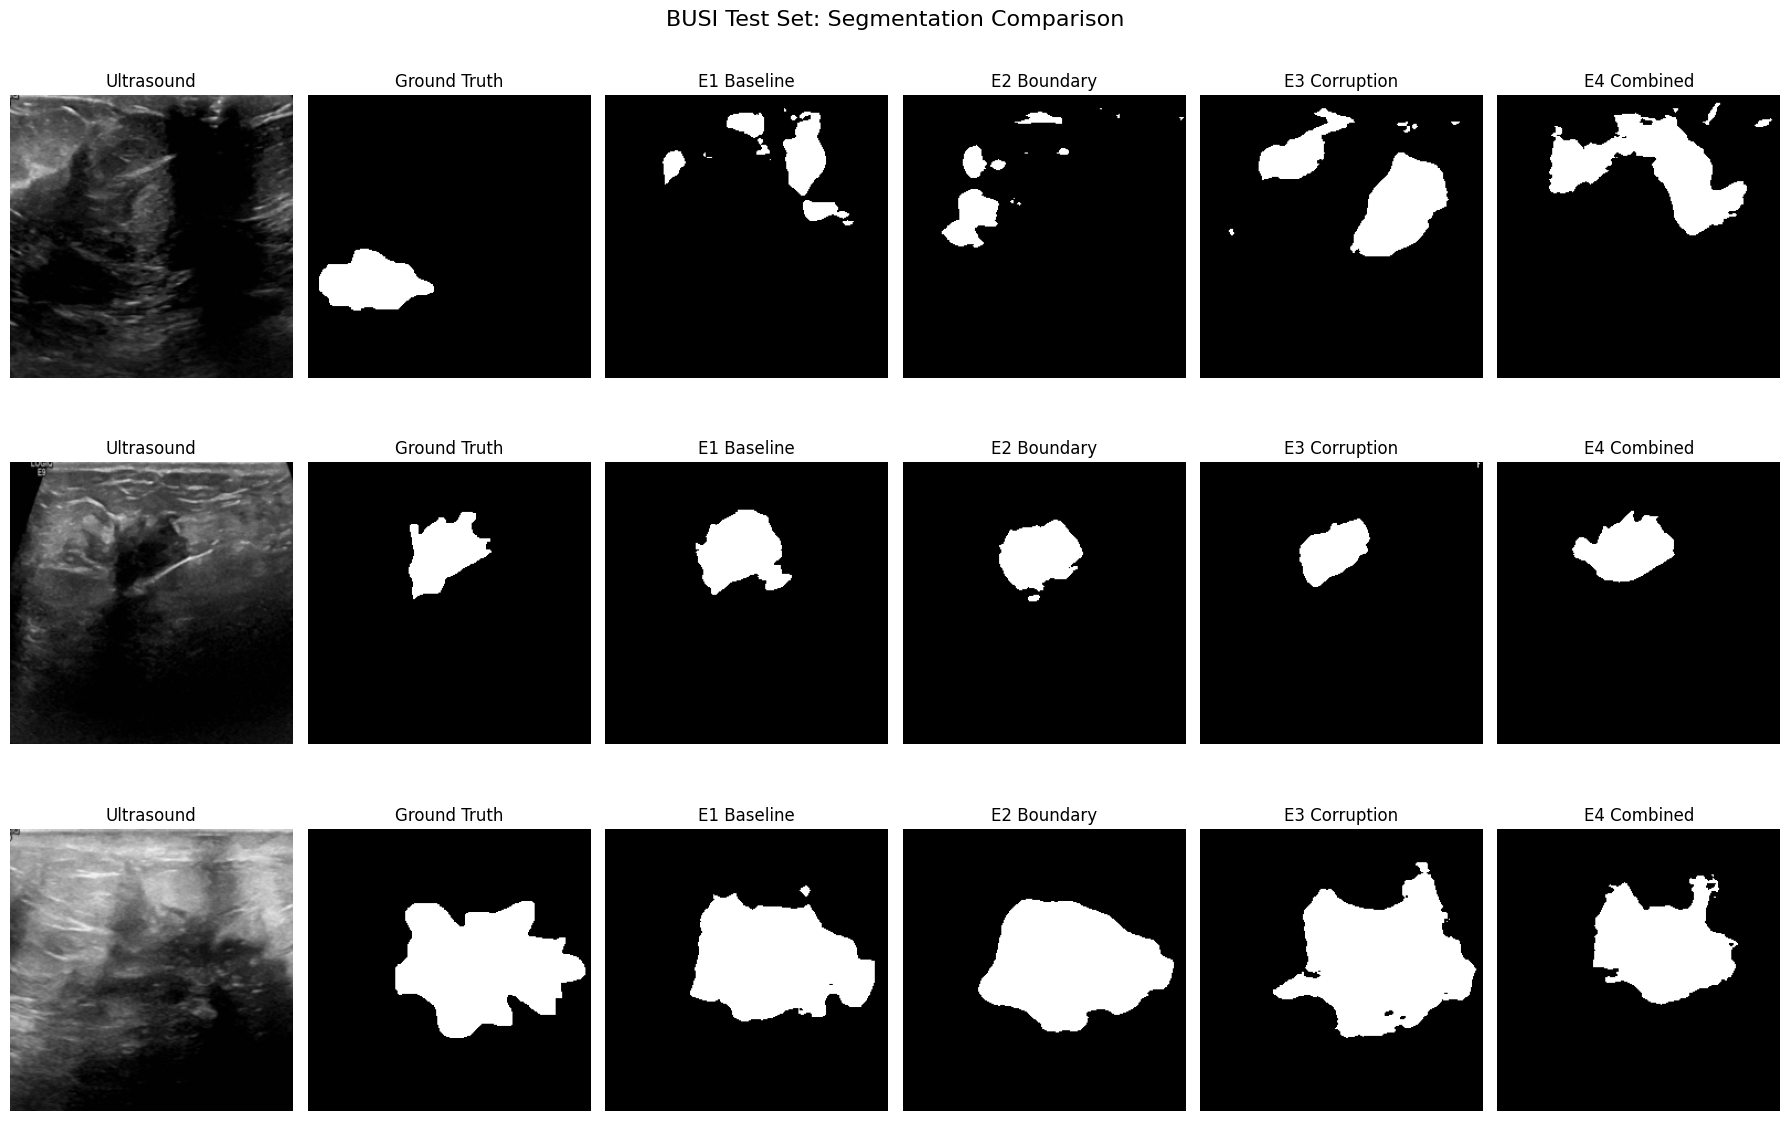

Saved visualization to AI512_Project/segmentation_visual_comparison.png


In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/AI512_Project"

EXPERIMENTS = {
    "E1 Baseline": "baseline_results",
    "E2 Boundary": "E2_boundary",
    "E3 Corruption": "E3_corruption",
    "E4 Combined": "E4_combined",
}

# Load saved best checkpoints
models = {}

for name, folder in EXPERIMENTS.items():
    path = os.path.join(BASE_DIR, folder, "best_model.pth")

    model = UltraLight_VM_UNet(
        num_classes=1,
        input_channels=3,
        c_list=[8, 16, 24, 32, 48, 64],
        split_att="fc",
        bridge=True
    ).to(device)

    checkpoint = torch.load(
        path, map_location=device, weights_only=False
    )

    if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    else:
        state_dict = checkpoint

    model.load_state_dict(state_dict)
    model.eval()
    models[name] = model

print("All four models loaded successfully.")

# Collect lesion-positive examples from the test set
examples = []

with torch.inference_mode():
    for images, masks in test_loader:
        for i in range(images.shape[0]):
            if masks[i].sum().item() > 0:
                examples.append((
                    images[i].cpu(),
                    masks[i].cpu()
                ))
            if len(examples) >= 3:
                break
        if len(examples) >= 3:
            break

# Plot original, ground truth, and all four predictions
fig, axes = plt.subplots(
    len(examples), 6,
    figsize=(18, 4 * len(examples))
)

if len(examples) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, (image, mask) in enumerate(examples):
    img = image.permute(1, 2, 0).numpy()
    gt = mask.squeeze().numpy()

    axes[row, 0].imshow(np.clip(img, 0, 1))
    axes[row, 0].set_title("Ultrasound")

    axes[row, 1].imshow(gt, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Ground Truth")

    with torch.inference_mode():
        for col, (name, model) in enumerate(models.items(), start=2):
            pred = model(image.unsqueeze(0).to(device))
            pred = (pred.squeeze().cpu().numpy() >= 0.5).astype(np.uint8)

            axes[row, col].imshow(pred, cmap="gray", vmin=0, vmax=1)
            axes[row, col].set_title(name)

    for col in range(6):
        axes[row, col].axis("off")

plt.suptitle("BUSI Test Set: Segmentation Comparison", fontsize=16)
plt.tight_layout()
plt.savefig(
    os.path.join(BASE_DIR, "segmentation_visual_comparison.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Saved visualization to AI512_Project/segmentation_visual_comparison.png")

Training Curves

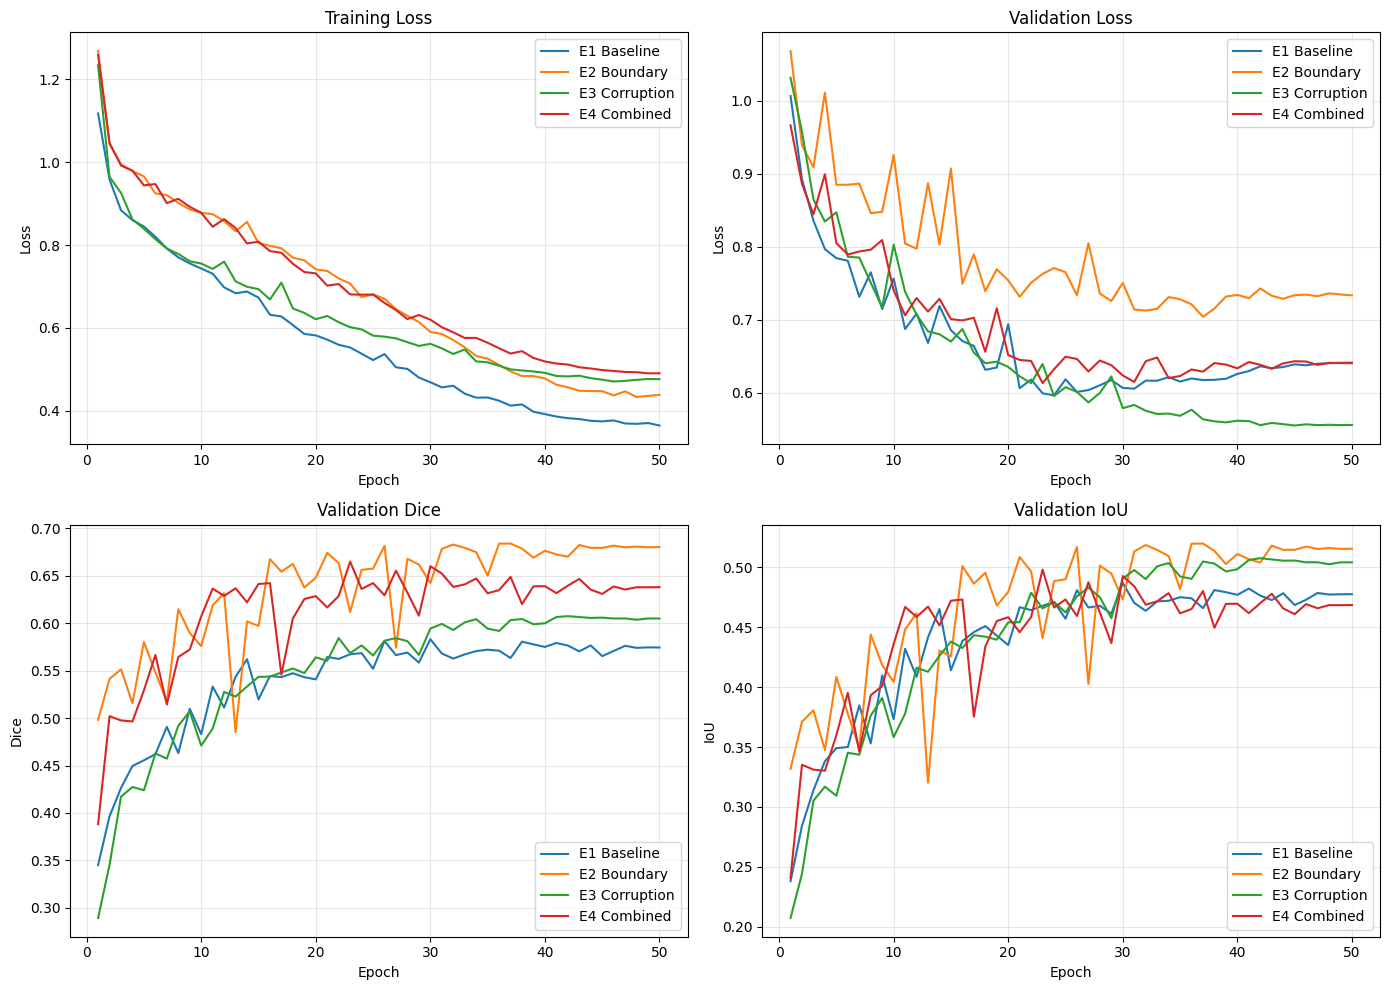

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

base = "/content/drive/MyDrive/AI512_Project"

experiments = {
    "E1 Baseline": "baseline_results",
    "E2 Boundary": "E2_boundary",
    "E3 Corruption": "E3_corruption",
    "E4 Combined": "E4_combined",
}

logs = {}

for name, folder in experiments.items():
    path = os.path.join(base, folder, "training_log.csv")
    logs[name] = pd.read_csv(path)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plots = [
    ("train_loss", "Training Loss"),
    ("val_loss", "Validation Loss"),
    ("val_dice", "Validation Dice"),
    ("val_iou", "Validation IoU"),
]

for ax, (column, title) in zip(axes.flat, plots):
    for name, df in logs.items():
        ax.plot(df["epoch"], df[column], label=name)

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title.split()[-1])
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(base, "training_curves_E1_E4.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [ ]:
# Inspect the test dataset structure and first few image-mask pairs

print("Dataset class:", type(test_loader.dataset))
print("Dataset attributes:", vars(test_loader.dataset).keys())

if hasattr(test_loader.dataset, "samples"):
    print("First samples:", test_loader.dataset.samples[:5])
elif hasattr(test_loader.dataset, "image_paths"):
    print("First images:", test_loader.dataset.image_paths[:5])
    print("First masks:", test_loader.dataset.mask_paths[:5])
else:
    print("Inspect the attributes above to identify image/mask path storage.")

Dataset class: <class '__main__.BUSIDataset'>
Dataset attributes: dict_keys(['data'])
Inspect the attributes above to identify image/mask path storage.


In [ ]:
# Inspect how BUSIDataset stores its samples
data = test_loader.dataset.data

print("Data type:", type(data))
print("Number of samples:", len(data))

print("\nFirst 3 samples:")
for i in range(min(3, len(data))):
    # Use .iloc to access rows by integer offset
    item = data.iloc[i].to_dict()
    print(f"\nSample {i}:")
    print("Type:", type(item))
    print("Content:", item)

Data type: <class 'pandas.core.frame.DataFrame'>
Number of samples: 117

First 3 samples:

Sample 0:
Type: <class 'dict'>
Content: {'image': '/content/BUSI_Processed/malignant/images/malignant (173).png', 'mask': '/content/BUSI_Processed/malignant/masks/malignant (173).png', 'category': 'malignant'}

Sample 1:
Type: <class 'dict'>
Content: {'image': '/content/BUSI_Processed/normal/images/normal (30).png', 'mask': '/content/BUSI_Processed/normal/masks/normal (30).png', 'category': 'normal'}

Sample 2:
Type: <class 'dict'>
Content: {'image': '/content/BUSI_Processed/malignant/images/malignant (70).png', 'mask': '/content/BUSI_Processed/malignant/masks/malignant (70).png', 'category': 'malignant'}


In [ ]:
import os
import pandas as pd
from PIL import Image
import numpy as np

df = test_loader.dataset.data

issues = []

for idx, row in df.iterrows():
    image_path = row["image"]
    mask_path = row["mask"]
    category = row["category"]

    # Check files exist
    if not os.path.isfile(image_path):
        issues.append((idx, "Missing image", image_path))
        continue

    if not os.path.isfile(mask_path):
        issues.append((idx, "Missing mask", mask_path))
        continue

    # Check image and mask dimensions
    with Image.open(image_path) as im:
        image_size = im.size

    with Image.open(mask_path) as m:
        mask_size = m.size
        mask_array = np.array(m)

    if image_size != mask_size:
        issues.append((idx, "Dimension mismatch", image_size, mask_size))

    # Normal images should have empty masks in this processed dataset
    if category == "normal" and np.any(mask_array > 0):
        issues.append((idx, "Normal image has nonempty mask", mask_path))

print("Total test samples:", len(df))
print("Pairing/file issues:", len(issues))

for issue in issues[:20]:
    print(issue)

if not issues:
    print("All file pairs passed these structural checks.")

Total test samples: 117
Pairing/file issues: 0
All file pairs passed these structural checks.


Qualtative Comparsion

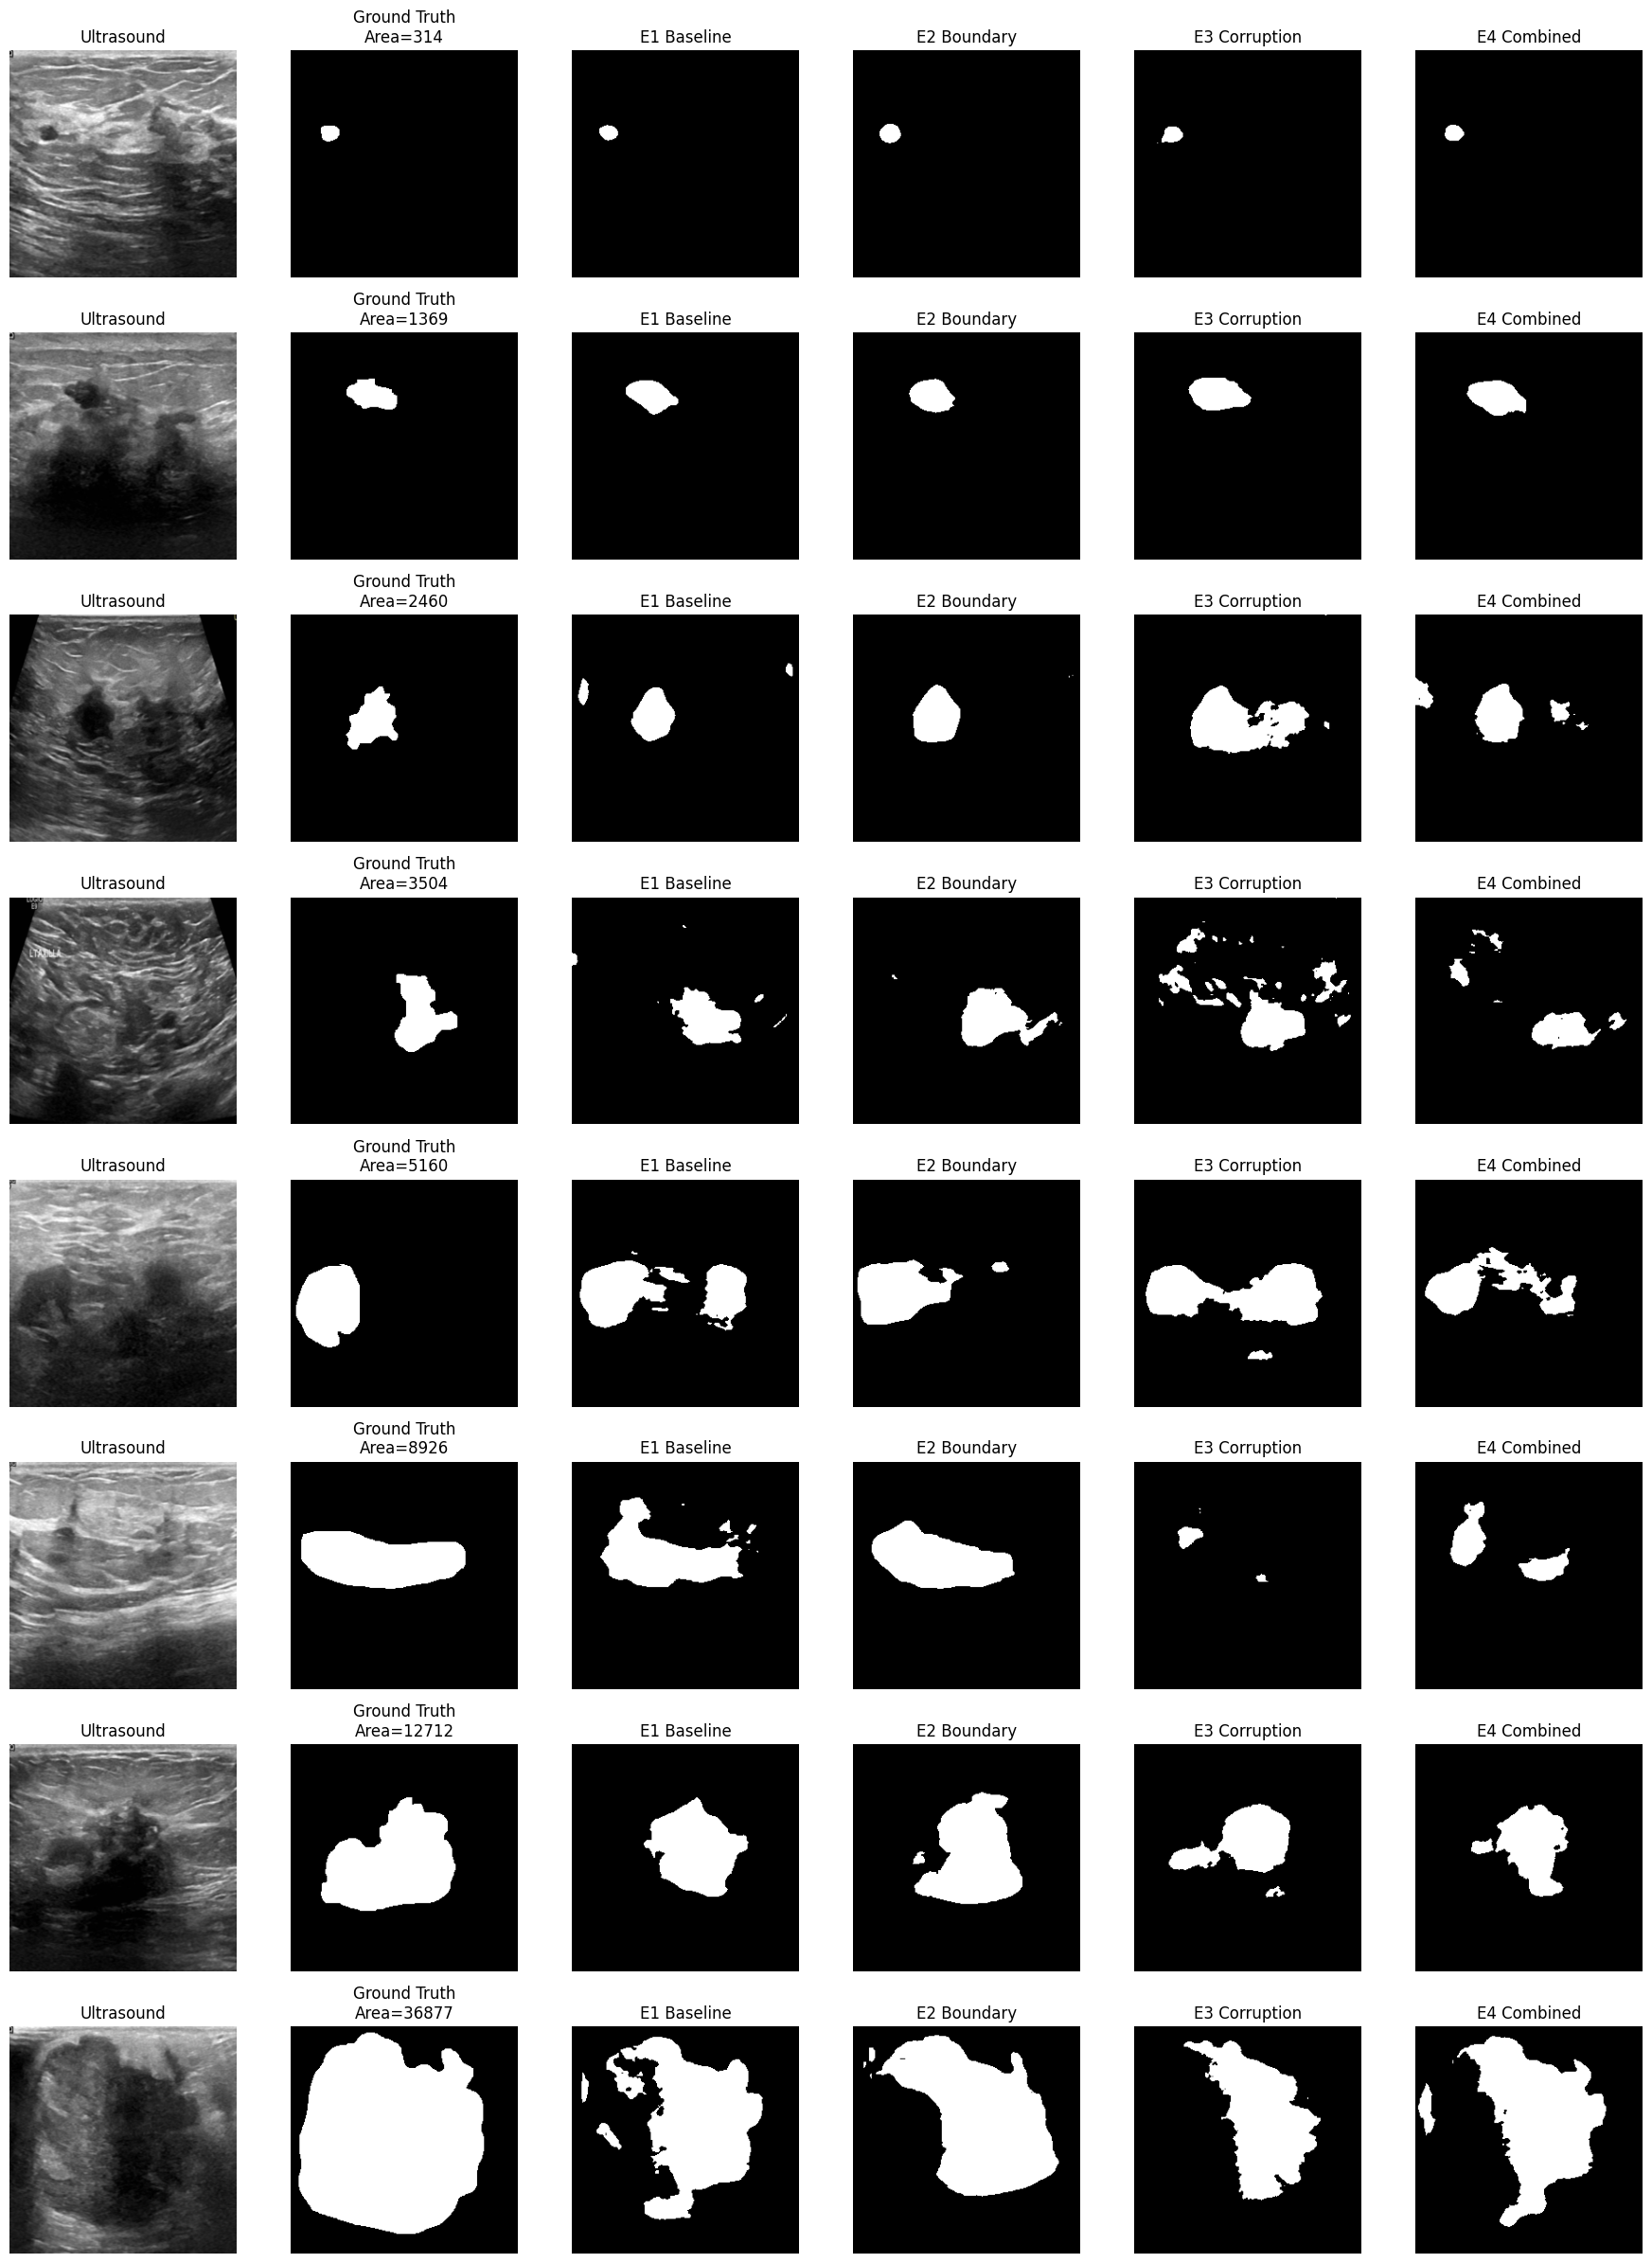

Saved: /content/drive/MyDrive/AI512_Project/qualitative_comparison_8_cases.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch

df = test_loader.dataset.data.reset_index(drop=True)

# Select lesion-positive cases with varied mask sizes.
positive = []

for idx, row in df.iterrows():
    if row["category"] == "normal":
        continue

    _, mask = test_loader.dataset[idx]
    mask = mask.squeeze().cpu().numpy() if torch.is_tensor(mask) else np.asarray(mask).squeeze()
    area = int((mask >= 0.5).sum())

    if area > 0:
        positive.append((idx, area))

positive.sort(key=lambda x: x[1])

# Choose 8 spread across the lesion-size range.
if len(positive) < 8:
    selected = positive
else:
    positions = np.linspace(0, len(positive) - 1, 8).round().astype(int)
    selected = [positive[p] for p in positions]

fig, axes = plt.subplots(len(selected), 6, figsize=(18, 3 * len(selected)))

if len(selected) == 1:
    axes = np.expand_dims(axes, axis=0)

with torch.inference_mode():
    for r, (idx, area) in enumerate(selected):
        image, mask = test_loader.dataset[idx][:2]

        image = image if torch.is_tensor(image) else torch.tensor(image)
        mask = mask if torch.is_tensor(mask) else torch.tensor(mask)

        image = image.float()
        mask_np = mask.squeeze().cpu().numpy()

        image_np = image.permute(1, 2, 0).cpu().numpy()
        axes[r, 0].imshow(np.clip(image_np, 0, 1))
        axes[r, 0].set_title("Ultrasound")

        axes[r, 1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
        axes[r, 1].set_title(f"Ground Truth\nArea={area}")

        for c, (name, model) in enumerate(models.items(), start=2):
            pred = model(image.unsqueeze(0).to(device))
            pred = (pred.squeeze().cpu().numpy() >= 0.5).astype(np.uint8)
            axes[r, c].imshow(pred, cmap="gray", vmin=0, vmax=1)
            axes[r, c].set_title(name)

        for c in range(6):
            axes[r, c].axis("off")

plt.tight_layout()

out = "/content/drive/MyDrive/AI512_Project/qualitative_comparison_8_cases.png"
plt.savefig(out, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", out)

Required Files to be Saved

In [ ]:
import os
import shutil

base = "/content/drive/MyDrive/AI512_Project"
out = os.path.join(base, "final_figures")
os.makedirs(out, exist_ok=True)

files = [
    "training_curves_E1_E4.png",
    "qualitative_comparison_8_cases.png",
    "segmentation_visual_comparison.png",
    "final_test_comparison.csv",
]

for filename in files:
    src = os.path.join(base, filename)

    if os.path.isfile(src):
        shutil.copy2(src, os.path.join(out, filename))
        print("SAVED:", filename)
    else:
        print("NOT FOUND:", filename)

print("\nFinal figures folder:", out)

SAVED: training_curves_E1_E4.png
SAVED: qualitative_comparison_8_cases.png
SAVED: segmentation_visual_comparison.png
SAVED: final_test_comparison.csv

Final figures folder: /content/drive/MyDrive/AI512_Project/final_figures


In [ ]:
import os

BASE = "/content/drive/MyDrive/AI512_Project"

paths = {
    "Baseline E1": f"{BASE}/baseline_results",
    "Boundary E2": f"{BASE}/E2_boundary",
    "Corruption E3": f"{BASE}/E3_corruption",
    "Combined E4": f"{BASE}/E4_combined",
    "Test split": f"{BASE}/splits",
}

for name, path in paths.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'MISSING'}")
    if os.path.exists(path):
        print(os.listdir(path)[:10])

Baseline E1: FOUND
['best_model.pth', 'training_log.csv']
Boundary E2: FOUND
['best_model.pth', 'training_log.csv', 'test_results.csv']
Corruption E3: FOUND
['best_model.pth', 'training_log.csv']
Combined E4: FOUND
['best_model.pth', 'training_log.csv']
Test split: FOUND
['train.csv', 'test.csv', 'val.csv']


Inspect the Test Split and Lesion Sizes

In [ ]:
import pandas as pd
import os

BASE = "/content/drive/MyDrive/AI512_Project"

test_csv = os.path.join(BASE, "splits", "test.csv")
test_df = pd.read_csv(test_csv)

print("Test samples:", len(test_df))
print("Columns:", test_df.columns.tolist())
print("\nFirst 5 rows:")
display(test_df.head())

print("\nDataset class available:", "BUSIDataset" in globals())
print("Test loader available:", "test_loader" in globals())
print("Model class available:", "UltraLight_VM_UNet" in globals())

Test samples: 117
Columns: ['image', 'mask', 'category']

First 5 rows:


,image,mask,category
0,/content/BUSI_Processed/malignant/images/malig...,/content/BUSI_Processed/malignant/masks/malign...,malignant
1,/content/BUSI_Processed/normal/images/normal (...,/content/BUSI_Processed/normal/masks/normal (3...,normal
2,/content/BUSI_Processed/malignant/images/malig...,/content/BUSI_Processed/malignant/masks/malign...,malignant
3,/content/BUSI_Processed/malignant/images/malig...,/content/BUSI_Processed/malignant/masks/malign...,malignant
4,/content/BUSI_Processed/malignant/images/malig...,/content/BUSI_Processed/malignant/masks/malign...,malignant



Dataset class available: False
Test loader available: False
Model class available: True


In [ ]:
import os
import inspect
import torch

print("Model constructor:")
print(inspect.signature(UltraLight_VM_UNet))

print("\nDevice:", "cuda" if torch.cuda.is_available() else "cpu")

test_df = pd.read_csv(
    "/content/drive/MyDrive/AI512_Project/splits/test.csv"
)

for col in ["image", "mask"]:
    path = test_df.iloc[0][col]
    print(f"\n{col}: {path}")
    print("Exists:", os.path.exists(path))

print("\nModel definition module:", UltraLight_VM_UNet.__module__)

Model constructor:
(num_classes=1, input_channels=3, c_list=[8, 16, 24, 32, 48, 64], split_att='fc', bridge=True)

Device: cuda

image: /content/BUSI_Processed/malignant/images/malignant (112).png
Exists: True

mask: /content/BUSI_Processed/malignant/masks/malignant (112).png
Exists: True

Model definition module: models.UltraLight_VM_UNet


Re Build the Test Dataset and Loader

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

BASE = "/content/drive/MyDrive/AI512_Project"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

test_df = pd.read_csv(f"{BASE}/splits/test.csv")

class BUSITestDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)
        self.image_transform = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor()
        ])
        self.mask_transform = transforms.Compose([
            transforms.Resize(
                (256, 256),
                interpolation=transforms.InterpolationMode.NEAREST
            ),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["image"]).convert("RGB")
        mask = Image.open(row["mask"]).convert("L")

        image = self.image_transform(image)
        mask = self.mask_transform(mask)
        mask = (mask > 0.5).float()

        return image, mask, row["category"]

test_dataset = BUSITestDataset(test_df)
test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

images, masks, categories = next(iter(test_loader))

print("Device:", DEVICE)
print("Test samples:", len(test_dataset))
print("Image shape:", images.shape)
print("Mask shape:", masks.shape)
print("Mask values:", torch.unique(masks))
print("First image category:", categories[0])

Device: cuda
Test samples: 117
Image shape: torch.Size([1, 3, 256, 256])
Mask shape: torch.Size([1, 1, 256, 256])
Mask values: tensor([0., 1.])
First image category: malignant


Small vs Large Lesion Evaluation

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms

BASE = "/content/drive/MyDrive/AI512_Project"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_dirs = {
    "E1_Baseline": f"{BASE}/baseline_results",
    "E2_Boundary": f"{BASE}/E2_boundary",
    "E3_Corruption": f"{BASE}/E3_corruption",
    "E4_Combined": f"{BASE}/E4_combined",
}

# Calculate lesion areas from ground-truth masks
records = []
to_tensor = transforms.ToTensor()

for i, row in test_df.reset_index(drop=True).iterrows():
    mask = Image.open(row["mask"]).convert("L").resize(
        (256, 256), Image.Resampling.NEAREST
    )
    mask = np.array(mask) > 127
    area = int(mask.sum())

    records.append({
        "index": i,
        "category": row["category"],
        "area_pixels": area,
        "area_fraction": area / (256 * 256),
        "size_group": "normal" if area == 0 else "pending"
    })

area_df = pd.DataFrame(records)
positive = area_df[area_df["area_pixels"] > 0]

if positive.empty:
    raise ValueError("No lesion-positive masks found in the test set.")

# Median split among lesion-positive test images
median_area = positive["area_pixels"].median()
area_df.loc[area_df["area_pixels"] > 0, "size_group"] = np.where(
    area_df.loc[area_df["area_pixels"] > 0, "area_pixels"] <= median_area,
    "small",
    "large"
)

print("Lesion-area median:", median_area, "pixels")
print("Groups:\n", area_df["size_group"].value_counts().to_string())

# Load and evaluate each saved checkpoint
all_results = []

for model_name, folder in checkpoint_dirs.items():
    ckpt_path = os.path.join(folder, "best_model.pth")
    if not os.path.exists(ckpt_path):
        print("Skipping missing checkpoint:", ckpt_path)
        continue

    model = UltraLight_VM_UNet(
        num_classes=1,
        input_channels=3,
        c_list=[8, 16, 24, 32, 48, 64],
        split_att="fc",
        bridge=True
    ).to(DEVICE)

    checkpoint = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)

    if isinstance(checkpoint, dict):
        state = checkpoint.get(
            "model_state_dict",
            checkpoint.get("state_dict", checkpoint)
        )
    else:
        state = checkpoint

    model.load_state_dict(state)
    model.eval()

    for i, row in test_df.reset_index(drop=True).iterrows():
        image = Image.open(row["image"]).convert("RGB").resize(
            (256, 256), Image.Resampling.BILINEAR
        )
        x = to_tensor(image).unsqueeze(0).to(DEVICE)
        gt = torch.from_numpy(
            np.array(
                Image.open(row["mask"]).convert("L").resize(
                    (256, 256), Image.Resampling.NEAREST
                )
            ) > 127
        ).to(DEVICE)

        with torch.no_grad():
            pred = model(x)
            if isinstance(pred, (tuple, list)):
                pred = pred[0]
            if pred.ndim == 3:
                pred = pred.unsqueeze(1)

            # The model used in our earlier experiments outputs sigmoid probabilities.
            pred_mask = pred.squeeze().float() >= 0.5

        intersection = (pred_mask & gt).sum().item()
        pred_area = pred_mask.sum().item()
        gt_area = gt.sum().item()
        dice = (2 * intersection) / (pred_area + gt_area) if pred_area + gt_area else 1.0
        union = pred_area + gt_area - intersection
        iou = intersection / union if union else 1.0

        all_results.append({
            "model": model_name,
            "index": i,
            "size_group": area_df.loc[i, "size_group"],
            "dice": dice,
            "iou": iou
        })

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print("Completed:", model_name)

results_df = pd.DataFrame(all_results)
summary = (
    results_df[results_df["size_group"].isin(["small", "large"])]
    .groupby(["model", "size_group"])
    .agg(
        images=("index", "count"),
        mean_dice=("dice", "mean"),
        mean_iou=("iou", "mean")
    )
    .reset_index()
)

out_path = f"{BASE}/lesion_size_evaluation.csv"
summary.to_csv(out_path, index=False)

print("\nSMALL vs LARGE LESION RESULTS")
display(summary.round(4))
print("Saved to:", out_path)

Lesion-area median: 4179.0 pixels
Groups:
 size_group
small     49
large     48
normal    20
SC_Att_Bridge was used
Completed: E1_Baseline
SC_Att_Bridge was used
Completed: E2_Boundary
SC_Att_Bridge was used
Completed: E3_Corruption
SC_Att_Bridge was used
Completed: E4_Combined

SMALL vs LARGE LESION RESULTS


,model,size_group,images,mean_dice,mean_iou
0,E1_Baseline,large,48,0.7584,0.6321
1,E1_Baseline,small,49,0.7589,0.6627
2,E2_Boundary,large,48,0.7690,0.6586
3,E2_Boundary,small,49,0.7839,0.6944
4,E3_Corruption,large,48,0.7746,0.6584
5,E3_Corruption,small,49,0.7630,0.6689
6,E4_Combined,large,48,0.6992,0.5730
7,E4_Combined,small,49,0.7451,0.6516


Saved to: /content/drive/MyDrive/AI512_Project/lesion_size_evaluation.csv


In [ ]:
!pip -q install scipy scikit-image

Calculate Boundary IoU and HD95

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
from scipy.ndimage import distance_transform_edt, binary_erosion, binary_dilation

BASE = "/content/drive/MyDrive/AI512_Project"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_dirs = {
    "E1_Baseline": f"{BASE}/baseline_results",
    "E2_Boundary": f"{BASE}/E2_boundary",
    "E3_Corruption": f"{BASE}/E3_corruption",
    "E4_Combined": f"{BASE}/E4_combined",
}

def boundary_map(mask):
    mask = mask.astype(bool)
    return mask ^ binary_erosion(mask, structure=np.ones((3, 3)), border_value=0)

def boundary_iou(pred, gt, tolerance=2):
    pred_b = boundary_map(pred)
    gt_b = boundary_map(gt)

    pred_dilated = binary_dilation(pred_b, iterations=tolerance)
    gt_dilated = binary_dilation(gt_b, iterations=tolerance)

    intersection = (pred_b & gt_dilated).sum() + (gt_b & pred_dilated).sum()
    denominator = pred_b.sum() + gt_b.sum()

    return float(intersection / denominator) if denominator else 1.0

def hd95(pred, gt):
    pred = pred.astype(bool)
    gt = gt.astype(bool)

    if not pred.any() and not gt.any():
        return 0.0
    if not pred.any() or not gt.any():
        return float("nan")

    pred_b = boundary_map(pred)
    gt_b = boundary_map(gt)

    d_gt = distance_transform_edt(~gt_b)
    d_pred = distance_transform_edt(~pred_b)

    distances = np.concatenate([d_gt[pred_b], d_pred[gt_b]])
    return float(np.percentile(distances, 95))

results = []

for model_name, folder in checkpoint_dirs.items():
    ckpt_path = os.path.join(folder, "best_model.pth")

    model = UltraLight_VM_UNet(
        num_classes=1,
        input_channels=3,
        c_list=[8, 16, 24, 32, 48, 64],
        split_att="fc",
        bridge=True
    ).to(DEVICE)

    checkpoint = torch.load(
        ckpt_path, map_location=DEVICE, weights_only=False
    )
    state = checkpoint.get(
        "model_state_dict",
        checkpoint.get("state_dict", checkpoint)
    ) if isinstance(checkpoint, dict) else checkpoint

    model.load_state_dict(state)
    model.eval()

    for i, row in test_df.reset_index(drop=True).iterrows():
        image = Image.open(row["image"]).convert("RGB").resize(
            (256, 256), Image.Resampling.BILINEAR
        )
        gt_image = Image.open(row["mask"]).convert("L").resize(
            (256, 256), Image.Resampling.NEAREST
        )

        x = transforms.ToTensor()(image).unsqueeze(0).to(DEVICE)
        gt = np.array(gt_image) > 127

        with torch.no_grad():
            pred = model(x)
            if isinstance(pred, (tuple, list)):
                pred = pred[0]
            if pred.ndim == 3:
                pred = pred.unsqueeze(1)
            pred = (pred.squeeze().float() >= 0.5).cpu().numpy()

        # Both masks empty: boundary metrics are perfect by convention.
        # One empty and one non-empty: boundary IoU = 0, HD95 undefined.
        if not pred.any() and not gt.any():
            biou, h95 = 1.0, 0.0
        elif not pred.any() or not gt.any():
            biou, h95 = 0.0, np.nan
        else:
            biou = boundary_iou(pred, gt, tolerance=2)
            h95 = hd95(pred, gt)

        results.append({
            "model": model_name,
            "index": i,
            "category": row["category"],
            "boundary_iou": biou,
            "hd95_pixels": h95
        })

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print("Completed:", model_name)

boundary_df = pd.DataFrame(results)

summary = boundary_df.groupby("model").agg(
    mean_boundary_iou=("boundary_iou", "mean"),
    mean_hd95_pixels=("hd95_pixels", "mean"),
    hd95_valid_images=("hd95_pixels", "count")
).reset_index()

display(summary.round(4))

boundary_df.to_csv(f"{BASE}/boundary_metrics_per_image.csv", index=False)
summary.to_csv(f"{BASE}/boundary_metrics_summary.csv", index=False)

print("Saved per-image and summary metrics to:", BASE)

SC_Att_Bridge was used
Completed: E1_Baseline
SC_Att_Bridge was used
Completed: E2_Boundary
SC_Att_Bridge was used
Completed: E3_Corruption
SC_Att_Bridge was used
Completed: E4_Combined


,model,mean_boundary_iou,mean_hd95_pixels,hd95_valid_images
0,E1_Baseline,0.3105,31.4383,96
1,E2_Boundary,0.3747,23.4075,99
2,E3_Corruption,0.3458,23.8433,98
3,E4_Combined,0.3197,30.6900,99


Saved per-image and summary metrics to: /content/drive/MyDrive/AI512_Project


Corruption Robustness Evaluation

In [ ]:

import os
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageEnhance
from torchvision import transforms

BASE = "/content/drive/MyDrive/AI512_Project"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_dirs = {
    "E1_Baseline": f"{BASE}/baseline_results",
    "E2_Boundary": f"{BASE}/E2_boundary",
    "E3_Corruption": f"{BASE}/E3_corruption",
    "E4_Combined": f"{BASE}/E4_combined",
}

to_tensor = transforms.ToTensor()
rng = np.random.default_rng(42)

def corrupt_image(pil_img, corruption, severity):
    # Operate on float RGB pixels in [0, 1]
    arr = np.asarray(pil_img.convert("RGB"), dtype=np.float32) / 255.0

    if corruption == "clean":
        out = arr
    elif corruption == "gaussian":
        sigma = {1: 0.05, 2: 0.10, 3: 0.20}[severity]
        noise = rng.normal(0, sigma, arr.shape).astype(np.float32)
        out = arr + noise
    elif corruption == "speckle":
        sigma = {1: 0.10, 2: 0.20, 3: 0.30}[severity]
        noise = rng.normal(0, sigma, arr.shape).astype(np.float32)
        out = arr + arr * noise
    elif corruption == "low_contrast":
        factor = {1: 0.75, 2: 0.50, 3: 0.25}[severity]
        out = (arr - 0.5) * factor + 0.5
    else:
        raise ValueError(corruption)

    out = np.clip(out, 0, 1)
    return Image.fromarray((out * 255).round().astype(np.uint8))

def dice_iou(pred, gt):
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    intersection = np.logical_and(pred, gt).sum()
    denom = pred.sum() + gt.sum()
    dice = (2 * intersection / denom) if denom else 1.0
    union = np.logical_or(pred, gt).sum()
    iou = (intersection / union) if union else 1.0
    return dice, iou

conditions = [
    ("clean", 0),
    ("gaussian", 1), ("gaussian", 2), ("gaussian", 3),
    ("speckle", 1), ("speckle", 2), ("speckle", 3),
    ("low_contrast", 1), ("low_contrast", 2), ("low_contrast", 3),
]

rows = []
test_rows = test_df.reset_index(drop=True).to_dict("records")

for model_name, folder in checkpoint_dirs.items():
    model = UltraLight_VM_UNet(
        num_classes=1,
        input_channels=3,
        c_list=[8, 16, 24, 32, 48, 64],
        split_att="fc",
        bridge=True
    ).to(DEVICE)

    ckpt = torch.load(
        os.path.join(folder, "best_model.pth"),
        map_location=DEVICE,
        weights_only=False
    )
    state = ckpt.get(
        "model_state_dict", ckpt.get("state_dict", ckpt)
    ) if isinstance(ckpt, dict) else ckpt
    model.load_state_dict(state)
    model.eval()

    for corruption, severity in conditions:
        dices, ious = [], []

        for row in test_rows:
            img = Image.open(row["image"]).convert("RGB").resize(
                (256, 256), Image.Resampling.BILINEAR
            )
            mask_img = Image.open(row["mask"]).convert("L").resize(
                (256, 256), Image.Resampling.NEAREST
            )
            gt = np.asarray(mask_img) > 127

            corrupted = corrupt_image(img, corruption, severity)
            x = to_tensor(corrupted).unsqueeze(0).to(DEVICE)

            with torch.no_grad():
                output = model(x)
                if isinstance(output, (tuple, list)):
                    output = output[0]
                if output.ndim == 3:
                    output = output.unsqueeze(1)
                pred = (output.squeeze().float() >= 0.5).cpu().numpy()

            d, j = dice_iou(pred, gt)
            dices.append(d)
            ious.append(j)

        rows.append({
            "model": model_name,
            "corruption": corruption,
            "severity": severity,
            "images": len(dices),
            "mean_dice": np.mean(dices),
            "mean_iou": np.mean(ious)
        })

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print("Completed:", model_name)

robustness_df = pd.DataFrame(rows)
robustness_df.to_csv(f"{BASE}/robustness_per_condition.csv", index=False)

display(robustness_df.round(4))

summary_path = f"{BASE}/robustness_summary.csv"
robustness_df.to_csv(summary_path, index=False)
print("Saved results:", summary_path)

SC_Att_Bridge was used
Completed: E1_Baseline
SC_Att_Bridge was used
Completed: E2_Boundary
SC_Att_Bridge was used
Completed: E3_Corruption
SC_Att_Bridge was used
Completed: E4_Combined


,model,corruption,severity,images,mean_dice,mean_iou
0,E1_Baseline,clean,0,117,0.6290,0.5369
1,E1_Baseline,gaussian,1,117,0.6115,0.5154
2,E1_Baseline,gaussian,2,117,0.5955,0.4983
3,E1_Baseline,gaussian,3,117,0.5354,0.4275
4,E1_Baseline,speckle,1,117,0.6230,0.5281
5,E1_Baseline,speckle,2,117,0.6080,0.5104
6,E1_Baseline,speckle,3,117,0.5861,0.4848
7,E1_Baseline,low_contrast,1,117,0.6197,0.5274
8,E1_Baseline,low_contrast,2,117,0.5645,0.4678
9,E1_Baseline,low_contrast,3,117,0.4135,0.3134


Saved results: /content/drive/MyDrive/AI512_Project/robustness_summary.csv


Measure parameters, inference latency, and FPS

In [ ]:

import os
import time
import numpy as np
import pandas as pd
import torch

BASE = "/content/drive/MyDrive/AI512_Project"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_dirs = {
    "E1_Baseline": f"{BASE}/baseline_results",
    "E2_Boundary": f"{BASE}/E2_boundary",
    "E3_Corruption": f"{BASE}/E3_corruption",
    "E4_Combined": f"{BASE}/E4_combined",
}

def make_model():
    return UltraLight_VM_UNet(
        num_classes=1,
        input_channels=3,
        c_list=[8, 16, 24, 32, 48, 64],
        split_att="fc",
        bridge=True
    ).to(DEVICE).eval()

results = []
x = torch.randn(1, 3, 256, 256, device=DEVICE)

for name, folder in checkpoint_dirs.items():
    model = make_model()

    checkpoint = torch.load(
        os.path.join(folder, "best_model.pth"),
        map_location=DEVICE,
        weights_only=False
    )
    state = checkpoint.get(
        "model_state_dict",
        checkpoint.get("state_dict", checkpoint)
    ) if isinstance(checkpoint, dict) else checkpoint
    model.load_state_dict(state)

    params = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    model_size_mb = os.path.getsize(
        os.path.join(folder, "best_model.pth")
    ) / (1024 ** 2)

    with torch.inference_mode():
        for _ in range(30):
            _ = model(x)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        timings = []
        for _ in range(200):
            start = time.perf_counter()
            _ = model(x)
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            timings.append((time.perf_counter() - start) * 1000)

    latency_ms = float(np.median(timings))
    results.append({
        "model": name,
        "parameters": params,
        "trainable_parameters": trainable,
        "checkpoint_size_MB": model_size_mb,
        "median_latency_ms_batch1": latency_ms,
        "approx_FPS_batch1": 1000 / latency_ms,
        "device": str(DEVICE)
    })

    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print("Completed:", name)

efficiency_df = pd.DataFrame(results)
display(efficiency_df.round(3))

out_path = f"{BASE}/efficiency_results.csv"
efficiency_df.to_csv(out_path, index=False)
print("Saved:", out_path)


SC_Att_Bridge was used
Completed: E1_Baseline
SC_Att_Bridge was used
Completed: E2_Boundary
SC_Att_Bridge was used
Completed: E3_Corruption
SC_Att_Bridge was used
Completed: E4_Combined


,model,parameters,trainable_parameters,checkpoint_size_MB,median_latency_ms_batch1,approx_FPS_batch1,device
0,E1_Baseline,49457,49457,0.709,21.931,45.597,cuda
1,E2_Boundary,49457,49457,0.709,28.516,35.068,cuda
2,E3_Corruption,49457,49457,0.230,22.390,44.664,cuda
3,E4_Combined,49457,49457,0.230,18.212,54.909,cuda


Saved: /content/drive/MyDrive/AI512_Project/efficiency_results.csv


Consistency Parameters

In [ ]:

import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms

BASE = "/content/drive/MyDrive/AI512_Project"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
to_tensor = transforms.ToTensor()

checkpoint_dirs = {
    "E1_Baseline": f"{BASE}/baseline_results",
    "E2_Boundary": f"{BASE}/E2_boundary",
    "E3_Corruption": f"{BASE}/E3_corruption",
    "E4_Combined": f"{BASE}/E4_combined",
}

rows = []
test_rows = test_df.reset_index(drop=True).to_dict("records")

for name, folder in checkpoint_dirs.items():
    model = UltraLight_VM_UNet(
        num_classes=1,
        input_channels=3,
        c_list=[8, 16, 24, 32, 48, 64],
        split_att="fc",
        bridge=True
    ).to(DEVICE).eval()

    ckpt = torch.load(
        os.path.join(folder, "best_model.pth"),
        map_location=DEVICE,
        weights_only=False
    )
    state = ckpt.get(
        "model_state_dict", ckpt.get("state_dict", ckpt)
    ) if isinstance(ckpt, dict) else ckpt
    model.load_state_dict(state)

    image_dice, image_iou = [], []
    positive_dice, positive_iou = [], []
    total_intersection = 0
    total_pred = 0
    total_gt = 0
    total_union = 0

    with torch.inference_mode():
        for row in test_rows:
            img = Image.open(row["image"]).convert("RGB").resize(
                (256, 256), Image.Resampling.BILINEAR
            )
            mask_img = Image.open(row["mask"]).convert("L").resize(
                (256, 256), Image.Resampling.NEAREST
            )
            gt = np.asarray(mask_img) > 127

            x = to_tensor(img).unsqueeze(0).to(DEVICE)
            output = model(x)
            if isinstance(output, (tuple, list)):
                output = output[0]
            if output.ndim == 3:
                output = output.unsqueeze(1)
            pred = (output.squeeze().float() >= 0.5).cpu().numpy()

            inter = np.logical_and(pred, gt).sum()
            pred_area = pred.sum()
            gt_area = gt.sum()
            union = np.logical_or(pred, gt).sum()

            d = 2 * inter / (pred_area + gt_area) if pred_area + gt_area else 1.0
            j = inter / union if union else 1.0

            image_dice.append(d)
            image_iou.append(j)

            if gt_area > 0:
                positive_dice.append(d)
                positive_iou.append(j)

            total_intersection += inter
            total_pred += pred_area
            total_gt += gt_area
            total_union += union

    rows.append({
        "model": name,
        "images": len(test_rows),
        "lesion_positive_images": len(positive_dice),
        "mean_image_dice_all": np.mean(image_dice),
        "mean_image_iou_all": np.mean(image_iou),
        "mean_dice_lesion_positive": np.mean(positive_dice),
        "mean_iou_lesion_positive": np.mean(positive_iou),
        "global_pixel_dice": (
            2 * total_intersection / (total_pred + total_gt)
            if total_pred + total_gt else 1.0
        ),
        "global_pixel_iou": (
            total_intersection / total_union if total_union else 1.0
        )
    })

    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print("Verified:", name)

verification_df = pd.DataFrame(rows)
display(verification_df.round(4))

out_path = f"{BASE}/metric_consistency_check.csv"
verification_df.to_csv(out_path, index=False)
print("Saved:", out_path)

# Compare the robustness table's clean results, if present
robust_path = f"{BASE}/robustness_summary.csv"
if os.path.exists(robust_path):
    old = pd.read_csv(robust_path)
    old_clean = old[
        (old["corruption"] == "clean") & (old["severity"] == 0)
    ][["model", "mean_dice", "mean_iou"]]

    print("\nPreviously saved clean robustness metrics:")
    display(old_clean.round(4))


SC_Att_Bridge was used
Verified: E1_Baseline
SC_Att_Bridge was used
Verified: E2_Boundary
SC_Att_Bridge was used
Verified: E3_Corruption
SC_Att_Bridge was used
Verified: E4_Combined


,model,images,lesion_positive_images,mean_image_dice_all,mean_image_iou_all,mean_dice_lesion_positive,mean_iou_lesion_positive,global_pixel_dice,global_pixel_iou
0,E1_Baseline,117,97,0.6290,0.5369,0.7587,0.6476,0.7337,0.5794
1,E2_Boundary,117,97,0.6695,0.5866,0.7766,0.6767,0.7817,0.6416
2,E3_Corruption,117,97,0.6544,0.5673,0.7687,0.6637,0.7812,0.6410
3,E4_Combined,117,97,0.6160,0.5251,0.7224,0.6127,0.7051,0.5446


Saved: /content/drive/MyDrive/AI512_Project/metric_consistency_check.csv

Previously saved clean robustness metrics:


,model,mean_dice,mean_iou
0,E1_Baseline,0.6290,0.5369
10,E2_Boundary,0.6695,0.5866
20,E3_Corruption,0.6544,0.5673
30,E4_Combined,0.6160,0.5251


E2 and E3 Audit

In [ ]:

# Audit executed notebook cells for E2 and E3 implementation details
from IPython import get_ipython

history = get_ipython().user_ns.get("In", [])
keywords = [
    "boundary", "lesion_size", "lesion size", "small_lesion",
    "consistency", "teacher", "student", "kl_div",
    "corruption", "speckle", "gaussian", "poisson",
    "contrast", "loss", "weight", "criterion"
]

for cell_no, source in enumerate(history):
    if not source or not source.strip():
        continue

    matches = [k for k in keywords if k in source.lower()]
    if matches:
        print(f"\n{'='*70}")
        print(f"CELL {cell_no} | Keywords: {', '.join(matches)}")
        print(source[:5000])
        if len(source) > 5000:
            print("... [truncated]")



CELL 14 | Keywords: boundary, corruption
import os

BASE = "/content/drive/MyDrive/AI512_Project"

paths = {
    "Baseline E1": f"{BASE}/baseline_results",
    "Boundary E2": f"{BASE}/E2_boundary",
    "Corruption E3": f"{BASE}/E3_corruption",
    "Combined E4": f"{BASE}/E4_combined",
    "Test split": f"{BASE}/splits",
}

for name, path in paths.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'MISSING'}")
    if os.path.exists(path):
        print(os.listdir(path)[:10])

CELL 23 | Keywords: boundary, lesion_size, corruption, weight
import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms

BASE = "/content/drive/MyDrive/AI512_Project"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_dirs = {
    "E1_Baseline": f"{BASE}/baseline_results",
    "E2_Boundary": f"{BASE}/E2_boundary",
    "E3_Corruption": f"{BASE}/E3_corruption",
    "E4_Combined": f"{BASE}/E4_combined",
}

# Ca

In [ ]:
from pathlib import Path

roots = [
    Path("/content/drive/MyDrive/AI512_Project"),
    Path("/content/UltraLight-VM-UNet")
]

extensions = {".ipynb", ".py"}

for root in roots:
    print(f"\n--- {root} ---")
    if not root.exists():
        print("Folder not found")
        continue

    for p in root.rglob("*"):
        if p.is_file() and p.suffix in extensions:
            if any(x in p.name.lower() for x in [
                "train", "experiment", "e1", "e2", "e3", "e4", "notebook"
            ]) or p.suffix == ".ipynb":
                print(p)


--- /content/drive/MyDrive/AI512_Project ---

--- /content/UltraLight-VM-UNet ---
/content/UltraLight-VM-UNet/train.py


In [ ]:
from pathlib import Path

roots = [
    Path("/content/UltraLight-VM-UNet"),
    Path("/content/drive/MyDrive/AI512_Project")
]

keywords = [
    "boundary_aware_loss",
    "boundary_weight",
    "boundary_loss",
    "lesion_size",
    "consistency_loss",
    "teacher_model",
    "student_model",
    "speckle",
    "poisson",
    "gaussian",
    "corruption",
    "optimizer.step",
    "loss.backward"
]

for root in roots:
    print(f"\n{'='*70}\nROOT: {root}")
    if not root.exists():
        print("Not found")
        continue

    for p in root.rglob("*.py"):
        try:
            lines = p.read_text(errors="ignore").splitlines()
        except Exception:
            continue

        hits = [
            (i + 1, line.strip())
            for i, line in enumerate(lines)
            if any(k in line.lower() for k in keywords)
        ]

        if hits:
            print(f"\n--- {p} ---")
            for line_no, line in hits:
                print(f"{line_no}: {line}")


ROOT: /content/UltraLight-VM-UNet

--- /content/UltraLight-VM-UNet/engine.py ---
40: loss.backward()
41: optimizer.step()

ROOT: /content/drive/MyDrive/AI512_Project


Poisson Noise Robustuness Evaluation

In [ ]:

# Poisson Noise Robustness Evaluation
# Evaluation only. No model training.

import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from pathlib import Path

PROJECT_DIR = "/content/drive/MyDrive/AI512_Project"

CHECKPOINTS = {
    "E1_Baseline": f"{PROJECT_DIR}/baseline_results/best_model.pth",
    "E2_Boundary": f"{PROJECT_DIR}/E2_boundary/best_model.pth",
    "E3_Corruption": f"{PROJECT_DIR}/E3_corruption/best_model.pth",
    "E4_Combined": f"{PROJECT_DIR}/E4_combined/best_model.pth",
}

# Fallback definition for device if not in globals
if "device" not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"'device' was not found in globals. Defined fallback: {device}")

required = ["test_df", "UltraLight_VM_UNet", "device"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        f"Missing notebook variables: {missing}. "
        "Run the existing setup/model-definition cells first."
    )

for name, path in CHECKPOINTS.items():
    if not os.path.isfile(path):
        raise FileNotFoundError(f"{name} checkpoint not found: {path}")

# Adapt to the existing dataset's column names.
print("Test dataframe columns:", list(test_df.columns))
print("Test images:", len(test_df))

class PoissonTestDataset(Dataset):
    def __init__(self, dataframe, level):
        self.df = dataframe.reset_index(drop=True)
        self.level = level
        self.to_tensor = transforms.ToTensor()
        self.mask_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_path = row["image"]
        mask_path = row["mask"]

        image = Image.open(image_path).convert("RGB").resize((256, 256))
        mask = Image.open(mask_path).convert("L").resize(
            (256, 256), Image.Resampling.NEAREST
        )

        x = np.asarray(image, dtype=np.float32) / 255.0

        # Poisson shot noise. Larger level = stronger corruption.
        # Scale controls the effective number of intensity counts.
        scale = {1: 100.0, 2: 30.0, 3: 10.0}[self.level]
        rng = np.random.default_rng(42000 + idx)
        corrupted = rng.poisson(np.clip(x, 0, 1) * scale) / scale
        corrupted = np.clip(corrupted, 0, 1).astype(np.float32)

        image_tensor = torch.from_numpy(corrupted).permute(2, 0, 1)
        mask_tensor = torch.from_numpy(
            (np.asarray(mask, dtype=np.float32) / 255.0 > 0.5).astype(
                np.float32
            )
        ).unsqueeze(0)

        return image_tensor, mask_tensor


def load_checkpoint(model, path):
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)

    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        state = checkpoint["model_state_dict"]
    else:
        state = checkpoint

    # Handle checkpoints saved from DataParallel models.
    state = {
        k.removeprefix("module."): v for k, v in state.items()
    }
    model.load_state_dict(state)
    return model.to(device).eval()


def evaluate_poisson(model, loader):
    dice_scores, iou_scores = [], []
    intersection_total = 0
    prediction_total = 0
    target_total = 0

    with torch.inference_mode():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device) >= 0.5

            outputs = model(images)
            if isinstance(outputs, (tuple, list)):
                outputs = outputs[0]

            preds = outputs >= 0.5
            intersection = (preds & masks).sum().item()
            pred_sum = preds.sum().item()
            target_sum = masks.sum().item()
            union = (preds | masks).sum().item()

            dice_scores.append(
                (2 * intersection + 1e-7) /
                (pred_sum + target_sum + 1e-7)
            )
            iou_scores.append(
                (intersection + 1e-7) / (union + 1e-7)
            )

            intersection_total += intersection
            prediction_total += pred_sum
            target_total += target_sum

    return {
        "Mean_Image_Dice": float(np.mean(dice_scores)),
        "Mean_Image_IoU": float(np.mean(iou_scores)),
        "Global_Pixel_Dice": (
            2 * intersection_total + 1e-7
        ) / (prediction_total + target_total + 1e-7),
    }


results = []

for level in [1, 2, 3]:
    dataset = PoissonTestDataset(test_df, level)
    loader = DataLoader(dataset, batch_size=1, shuffle=False, num_workers=0)

    for model_name, checkpoint_path in CHECKPOINTS.items():
        print(f"Evaluating {model_name}, Poisson level {level}...")

        model = UltraLight_VM_UNet(
            num_classes=1,
            input_channels=3,
            c_list=[8, 16, 24, 32, 48, 64],
            split_att="fc",
            bridge=True
        )

        model = load_checkpoint(model, checkpoint_path)
        metrics = evaluate_poisson(model, loader)

        results.append({
            "Model": model_name,
            "Noise": "Poisson",
            "Level": level,
            "Test_Images": len(dataset),
            **metrics
        })

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
display(results_df)

output_path = f"{PROJECT_DIR}/poisson_robustness_results.csv"
results_df.to_csv(output_path, index=False)
print(f"Saved results to: {output_path}")


'device' was not found in globals. Defined fallback: cuda
Test dataframe columns: ['image', 'mask', 'category']
Test images: 117
Evaluating E1_Baseline, Poisson level 1...
SC_Att_Bridge was used
Evaluating E2_Boundary, Poisson level 1...
SC_Att_Bridge was used
Evaluating E3_Corruption, Poisson level 1...
SC_Att_Bridge was used
Evaluating E4_Combined, Poisson level 1...
SC_Att_Bridge was used
Evaluating E1_Baseline, Poisson level 2...
SC_Att_Bridge was used
Evaluating E2_Boundary, Poisson level 2...
SC_Att_Bridge was used
Evaluating E3_Corruption, Poisson level 2...
SC_Att_Bridge was used
Evaluating E4_Combined, Poisson level 2...
SC_Att_Bridge was used
Evaluating E1_Baseline, Poisson level 3...
SC_Att_Bridge was used
Evaluating E2_Boundary, Poisson level 3...
SC_Att_Bridge was used
Evaluating E3_Corruption, Poisson level 3...
SC_Att_Bridge was used
Evaluating E4_Combined, Poisson level 3...
SC_Att_Bridge was used


,Model,Noise,Level,Test_Images,Mean_Image_Dice,Mean_Image_IoU,Global_Pixel_Dice
0,E1_Baseline,Poisson,1,117,0.621662,0.525901,0.713738
1,E2_Boundary,Poisson,1,117,0.668684,0.582523,0.766213
2,E3_Corruption,Poisson,1,117,0.633967,0.547229,0.759785
3,E4_Combined,Poisson,1,117,0.611876,0.520953,0.699903
4,E1_Baseline,Poisson,2,117,0.605234,0.506047,0.692011
5,E2_Boundary,Poisson,2,117,0.637804,0.547920,0.725091
6,E3_Corruption,Poisson,2,117,0.573177,0.477124,0.697180
7,E4_Combined,Poisson,2,117,0.612644,0.519445,0.691398
8,E1_Baseline,Poisson,3,117,0.552348,0.446627,0.643276
9,E2_Boundary,Poisson,3,117,0.531749,0.436516,0.634883


Saved results to: /content/drive/MyDrive/AI512_Project/poisson_robustness_results.csv


Poisson Robustness Comparsion for E1=E4

Existing robustness columns: ['model', 'corruption', 'severity', 'images', 'mean_dice', 'mean_iou']
Poisson columns: ['Model', 'Noise', 'Level', 'Test_Images', 'Mean_Image_Dice', 'Mean_Image_IoU', 'Global_Pixel_Dice']

Consolidated robustness results:


,Model,corruption,severity,images,Mean_Image_Dice,Mean_Image_IoU,Noise,Level,Test_Images,Global_Pixel_Dice
0,E1_Baseline,NaN,NaN,NaN,0.621662,0.525901,Poisson,1.0,117.0,0.713738
1,E2_Boundary,NaN,NaN,NaN,0.668684,0.582523,Poisson,1.0,117.0,0.766213
2,E3_Corruption,NaN,NaN,NaN,0.633967,0.547229,Poisson,1.0,117.0,0.759785
3,E4_Combined,NaN,NaN,NaN,0.611876,0.520953,Poisson,1.0,117.0,0.699903
4,E1_Baseline,NaN,NaN,NaN,0.605234,0.506047,Poisson,2.0,117.0,0.692011
5,E2_Boundary,NaN,NaN,NaN,0.637804,0.547920,Poisson,2.0,117.0,0.725091
6,E3_Corruption,NaN,NaN,NaN,0.573177,0.477124,Poisson,2.0,117.0,0.697180
7,E4_Combined,NaN,NaN,NaN,0.612644,0.519445,Poisson,2.0,117.0,0.691398
8,E1_Baseline,NaN,NaN,NaN,0.552348,0.446627,Poisson,3.0,117.0,0.643276
9,E2_Boundary,NaN,NaN,NaN,0.531749,0.436516,Poisson,3.0,117.0,0.634883



Saved CSV: /content/drive/MyDrive/AI512_Project/final_robustness_comparison.csv


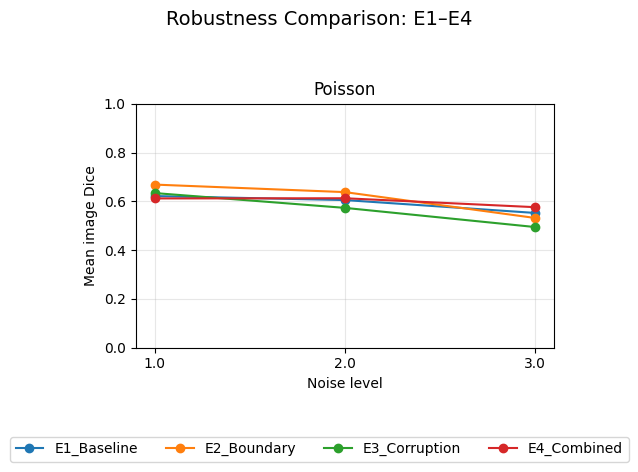

Saved plot: /content/drive/MyDrive/AI512_Project/final_robustness_comparison.png


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/AI512_Project"

EXISTING_CSV = os.path.join(
    PROJECT_DIR, "robustness_per_condition.csv"
)
POISSON_CSV = os.path.join(
    PROJECT_DIR, "poisson_robustness_results.csv"
)

# 1. Load both evaluation results
if not os.path.exists(EXISTING_CSV):
    raise FileNotFoundError(f"Missing file: {EXISTING_CSV}")

if not os.path.exists(POISSON_CSV):
    raise FileNotFoundError(f"Missing file: {POISSON_CSV}")

existing = pd.read_csv(EXISTING_CSV)
poisson = pd.read_csv(POISSON_CSV)

print("Existing robustness columns:", existing.columns.tolist())
print("Poisson columns:", poisson.columns.tolist())

# 2. Standardize the common columns
# Existing results may use different column names for noise conditions.
def standardize_columns(df):
    df = df.copy()
    aliases = {
        "model": "Model",
        "noise": "Noise",
        "condition": "Noise",
        "level": "Level",
        "noise_level": "Level",
        "mean_image_dice": "Mean_Image_Dice",
        "mean_dice": "Mean_Image_Dice",
        "dice": "Mean_Image_Dice",
        "mean_image_iou": "Mean_Image_IoU",
        "mean_iou": "Mean_Image_IoU",
        "iou": "Mean_Image_IoU",
        "global_pixel_dice": "Global_Pixel_Dice",
    }

    rename = {}
    for col in df.columns:
        normalized = col.strip().lower().replace(" ", "_")
        if normalized in aliases:
            rename[col] = aliases[normalized]

    return df.rename(columns=rename)

existing = standardize_columns(existing)
poisson = standardize_columns(poisson)

required = ["Model", "Mean_Image_Dice", "Mean_Image_IoU"]
for name, df in [("Existing", existing), ("Poisson", poisson)]:
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(
            f"{name} CSV is missing {missing}. "
            f"Available columns: {df.columns.tolist()}"
        )

# Add Poisson results to the existing conditions.
# Existing robustness results are preserved.
combined = pd.concat(
    [existing, poisson],
    ignore_index=True,
    sort=False
)

# Remove exact duplicate rows if any.
combined = combined.drop_duplicates()

# Normalize model labels for consistent sorting and display.
model_order = [
    "E1_Baseline",
    "E2_Boundary",
    "E3_Corruption",
    "E4_Combined"
]

combined["Model"] = combined["Model"].astype(str).str.strip()
combined["Noise"] = combined["Noise"].astype(str).str.strip()

# Save the consolidated per-condition results.
output_csv = os.path.join(
    PROJECT_DIR, "final_robustness_comparison.csv"
)
combined.to_csv(output_csv, index=False)

print("\nConsolidated robustness results:")
display(
    combined.sort_values(
        by=["Noise", "Level", "Model"],
        na_position="first"
    ).reset_index(drop=True)
)

print(f"\nSaved CSV: {output_csv}")

# 3. Generate Dice robustness plot
plot_df = combined.dropna(
    subset=["Model", "Noise", "Mean_Image_Dice"]
).copy()

# Make one subplot per corruption type.
noise_order = [
    "Clean", "Gaussian", "Speckle", "Low Contrast", "Poisson"
]

def noise_category(value):
    v = str(value).lower().replace("_", " ").strip()
    if "clean" in v:
        return "Clean"
    if "gaussian" in v:
        return "Gaussian"
    if "speckle" in v:
        return "Speckle"
    if "contrast" in v:
        return "Low Contrast"
    if "poisson" in v:
        return "Poisson"
    return value

plot_df["Noise_Category"] = plot_df["Noise"].map(noise_category)

categories = [
    n for n in noise_order
    if n in plot_df["Noise_Category"].unique()
]

if not categories:
    raise ValueError(
        "Could not identify noise categories. "
        f"Observed labels: {plot_df['Noise'].unique().tolist()}"
    )

fig, axes = plt.subplots(
    1, len(categories),
    figsize=(5 * len(categories), 4.5),
    squeeze=False
)
axes = axes.ravel()

for ax, category in zip(axes, categories):
    subset = plot_df[plot_df["Noise_Category"] == category]

    for model_name in model_order:
        model_data = subset[subset["Model"] == model_name].copy()
        if model_data.empty:
            continue

        if "Level" in model_data.columns:
            model_data = model_data.sort_values("Level")
            x = model_data["Level"].astype(str)
        else:
            x = range(len(model_data))

        ax.plot(
            x,
            model_data["Mean_Image_Dice"],
            marker="o",
            label=model_name
        )

    ax.set_title(category)
    ax.set_xlabel("Noise level")
    ax.set_ylabel("Mean image Dice")
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(
        handles, labels,
        loc="lower center",
        ncol=min(4, len(labels)),
        bbox_to_anchor=(0.5, -0.04)
    )

fig.suptitle(
    "Robustness Comparison: E1–E4",
    fontsize=14
)
plt.tight_layout(rect=[0, 0.10, 1, 0.93])

output_plot = os.path.join(
    PROJECT_DIR, "final_robustness_comparison.png"
)
fig.savefig(output_plot, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved plot: {output_plot}")


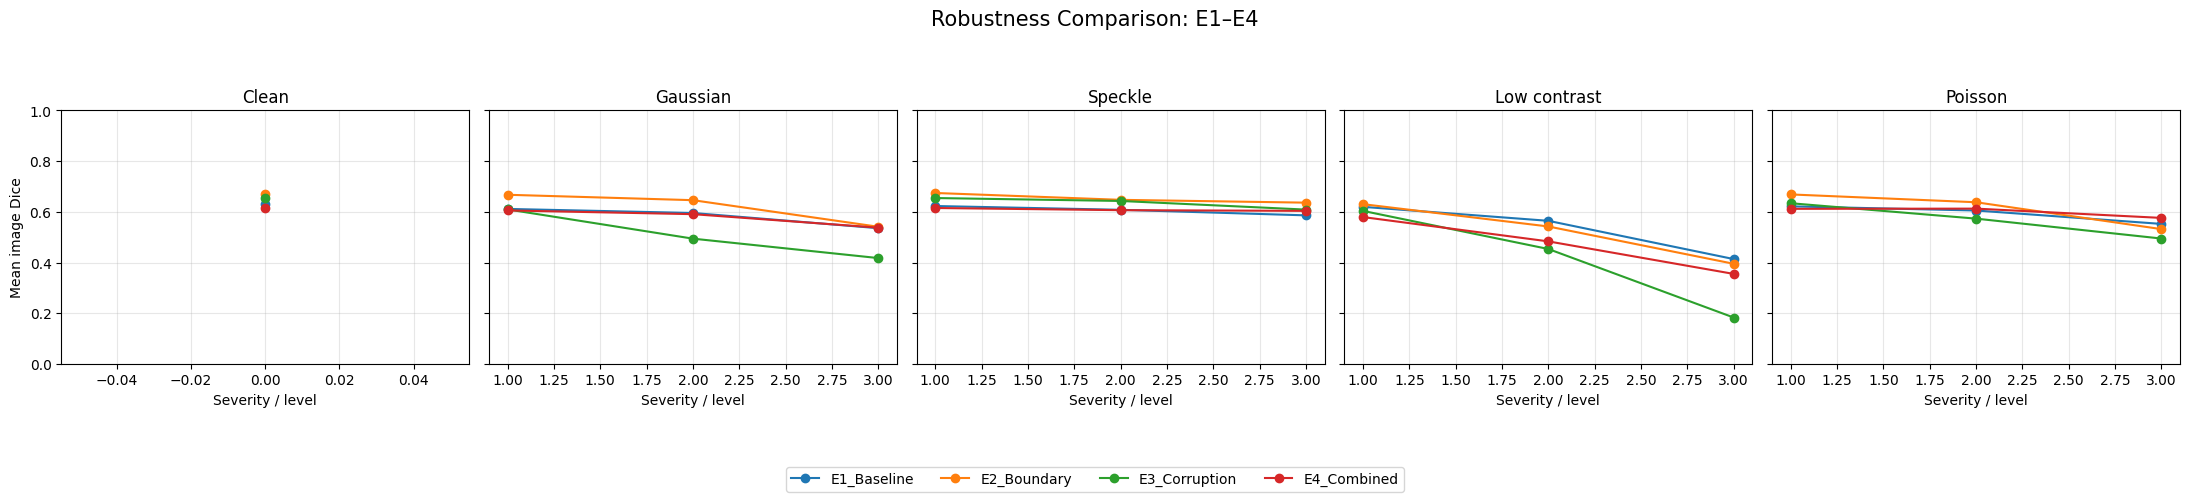

Saved complete robustness plot: /content/drive/MyDrive/AI512_Project/final_robustness_comparison.png

Conditions included:
Noise_Type
Gaussian        12
Low contrast    12
Speckle         12
Poisson         12
Clean            4


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

project = "/content/drive/MyDrive/AI512_Project"
df = pd.read_csv(os.path.join(project, "final_robustness_comparison.csv"))

# Combine the existing corruption/severity columns with Poisson's Noise/Level.
df["Noise_Type"] = df["Noise"].fillna(df["corruption"])
df["Noise_Level"] = df["Level"].fillna(df["severity"])

df["Noise_Type"] = (
    df["Noise_Type"].astype(str).str.lower()
    .str.replace("_", " ", regex=False)
)

df["Noise_Type"] = df["Noise_Type"].replace({
    "low contrast": "Low contrast",
    "gaussian": "Gaussian",
    "speckle": "Speckle",
    "poisson": "Poisson",
    "clean": "Clean"
})

model_order = [
    "E1_Baseline", "E2_Boundary",
    "E3_Corruption", "E4_Combined"
]
noise_order = ["Clean", "Gaussian", "Speckle", "Low contrast", "Poisson"]

fig, axes = plt.subplots(1, 5, figsize=(22, 4.8), sharey=True)

for ax, noise in zip(axes, noise_order):
    subset = df[df["Noise_Type"].str.lower() == noise.lower()]

    for model in model_order:
        part = subset[subset["Model"] == model].sort_values("Noise_Level")
        if part.empty:
            continue

        ax.plot(
            part["Noise_Level"],
            part["Mean_Image_Dice"],
            marker="o",
            label=model
        )

    ax.set_title(noise)
    ax.set_xlabel("Severity / level")
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1)

axes[0].set_ylabel("Mean image Dice")
handles, labels = axes[-1].get_legend_handles_labels()

# Use handles from whichever subplot contains the model lines.
if not handles:
    handles, labels = axes[0].get_legend_handles_labels()

fig.legend(handles, labels, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Robustness Comparison: E1–E4", fontsize=15)
plt.tight_layout(rect=[0, 0.12, 1, 0.92])

out = os.path.join(project, "final_robustness_comparison.png")
fig.savefig(out, dpi=300, bbox_inches="tight")
plt.show()

print("Saved complete robustness plot:", out)
print("\nConditions included:")
print(df["Noise_Type"].value_counts().to_string())


Checking All Delivrables

In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive/AI512_Project")

files_to_check = [
    "final_test_comparison.csv",
    "lesion_size_evaluation.csv",
    "boundary_metrics_summary.csv",
    "robustness_per_condition.csv",
    "poisson_robustness_results.csv",
    "final_robustness_comparison.csv",
    "efficiency_results.csv",
    "metric_consistency_check.csv",
    "training_curves_E1_E4.png",
    "final_figures/qualitative_comparison_8_cases.png",
    "final_figures/segmentation_visual_comparison.png",
    "final_figures/training_curves_E1_E4.png",
    "final_figures/final_test_comparison.csv",
]

print("AI512 REPORT ASSET CHECK")

for name in files_to_check:
    path = root / name
    print(f"{'FOUND' if path.exists() else 'MISSING':8} | {name}")

print("\nProject directory:", root)


AI512 REPORT ASSET CHECK
FOUND    | final_test_comparison.csv
FOUND    | lesion_size_evaluation.csv
FOUND    | boundary_metrics_summary.csv
FOUND    | robustness_per_condition.csv
FOUND    | poisson_robustness_results.csv
FOUND    | final_robustness_comparison.csv
FOUND    | efficiency_results.csv
FOUND    | metric_consistency_check.csv
FOUND    | training_curves_E1_E4.png
FOUND    | final_figures/qualitative_comparison_8_cases.png
FOUND    | final_figures/segmentation_visual_comparison.png
FOUND    | final_figures/training_curves_E1_E4.png
FOUND    | final_figures/final_test_comparison.csv

Project directory: /content/drive/MyDrive/AI512_Project
